# Crimes Analysis on US Populations
Project B.

Lets begin by adding and loading all the packages that will be useful along the notebook.

In [1]:
using Pkg
# Ensure required packages (uncomment to install if needed)
Pkg.add([
    "MLJ", 
    "MLJBase", 
    "MLJModels", 
    "MLJEnsembles", 
    "MLJLinearModels", 
    "DecisionTree", 
    "MLJDecisionTreeInterface",
    "NaiveBayes",
    "MLJNaiveBayesInterface", 
    "EvoTrees", 
    "CategoricalArrays", 
    "Random",
    "LIBSVM",           
    "MLJLIBSVMInterface", 
    "Plots",
    "MLJModelInterface",
    "CSV",       
    "DataFrames",      
    "UrlDownload",
    "XGBoost",
    "MultivariateStats",
    "MLJMultivariateStatsInterface",
    "TSne",
    "Optimisers",
    "MLJFlux",
    "NearestNeighborModels",
    "Flux",
    "Statistics",
    "StatsPlots",
    "PrettyTables",
    "Printf"
])

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`


In [2]:
using MLJ;
using Plots;
using TSne;
using DataFrames;
using CSV;
using CategoricalArrays;
using Random;
using Pkg;
PCA = MLJ.@load PCA pkg=MultivariateStats
ICA = MLJ.@load ICA pkg=MultivariateStats
LDA = MLJ.@load LDA pkg=MultivariateStats verbosity=0
ICA = MLJ.@load ICA pkg=MultivariateStats
# TSNE = MLJ.@load TSNE pkg=TSne

LogisticClassifier = @load LogisticClassifier pkg=MLJLinearModels verbosity=0
GaussianNBClassifier = @load GaussianNBClassifier pkg=NaiveBayes verbosity=0


┌ Info: For silent loading, specify `verbosity=0`. 
└ @ Main /Users/albertosc/.julia/packages/MLJModels/ziReN/src/loading.jl:159


import MLJMultivariateStatsInterface ✔
import MLJMultivariateStatsInterface ✔


┌ Info: For silent loading, specify `verbosity=0`. 
└ @ Main /Users/albertosc/.julia/packages/MLJModels/ziReN/src/loading.jl:159
┌ Info: For silent loading, specify `verbosity=0`. 
└ @ Main /Users/albertosc/.julia/packages/MLJModels/ziReN/src/loading.jl:159


import MLJMultivariateStatsInterface ✔


MLJNaiveBayesInterface.GaussianNBClassifier

In [90]:
# Finally lets import the functions created during the previous assignments
include("src/Preprocessing.jl")
include("src/Sampling.jl")
include("src/Training.jl")
include("src/Output.jl")
include("src/Ensembles.jl")


┌ Info: For silent loading, specify `verbosity=0`. 
└ @ Main.Training /Users/albertosc/.julia/packages/MLJModels/ziReN/src/loading.jl:159


import MLJLIBSVMInterface ✔


LoadError: LoadError: UndefVarError: `title_prefix` not defined in `Main.Ensembles`
Suggestion: check for spelling errors or missing imports.
in expression starting at /Users/albertosc/Development/UDC/ML1/proyecto_ml1/src/Ensembles.jl:1

In [91]:
using .Sampling
using .Preprocessing
using .Training
using .Output
using .Ensembles

## Loading data

The next phase is to load the data of our dataset and clean it. The dataset cames as two files the first one is a CSV with all the data (`communities.data`) and the second one (`communities.names`) gives information about the preprocessing being done.

The data cames with missing values which are marked as '?', these values where transformed into missing values to help the dataframe detect the type of each column.

Notice that we won't normalize the data as it has been previously normalize between 0 and 1 retaining their distribution and skew.

In [5]:
Random.seed!(1234); # For reproducibility

# Laoding data
df = CSV.read("data/communities.data", DataFrame; header=false, missingstring="?");
df

Row,Column1,Column2,Column3,Column4,Column5,Column6,Column7,Column8,Column9,Column10,Column11,Column12,Column13,Column14,Column15,Column16,Column17,Column18,Column19,Column20,Column21,Column22,Column23,Column24,Column25,Column26,Column27,Column28,Column29,Column30,Column31,Column32,Column33,Column34,Column35,Column36,Column37,Column38,Column39,Column40,Column41,Column42,Column43,Column44,Column45,Column46,Column47,Column48,Column49,Column50,Column51,Column52,Column53,Column54,Column55,Column56,Column57,Column58,Column59,Column60,Column61,Column62,Column63,Column64,Column65,Column66,Column67,Column68,Column69,Column70,Column71,Column72,Column73,Column74,Column75,Column76,Column77,Column78,Column79,Column80,Column81,Column82,Column83,Column84,Column85,Column86,Column87,Column88,Column89,Column90,Column91,Column92,Column93,Column94,Column95,Column96,Column97,Column98,Column99,Column100,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.0,0.0,0.19,0.3,0.73,0.64,⋯
5,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.71,0.46,0.43,0.41,0.28,0.0,0.74,0.51,0.48,0.0,0.06,0.25,0.3,0.33,0.12,0.65,0.67,0.38,0.42,0.46,0.22,0.27,0.2,0.21,0.51,0.91,0.91,0.89,0.85,0.4,0.6,0.0,0.06,0.0,0.03,0.07,0.2,0.27,0.01,0.02,

After importing the data we change the name of the columns by its corresponding one and then we make a first quick analysis.

In [6]:
#TODO: Add column names to CSV
header_string = "state, county, community, communityname, fold, population, householdsize, racepctblack, racePctWhite, racePctAsian, racePctHisp, agePct12t21, agePct12t29, agePct16t24, agePct65up, numbUrban, pctUrban, medIncome, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, medFamInc, perCapInc, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, NumUnderPov, PctPopUnderPov, PctLess9thGrade, PctNotHSGrad, PctBSorMore, PctUnemployed, PctEmploy, PctEmplManu, PctEmplProfServ, PctOccupManu, PctOccupMgmtProf, MalePctDivorce, MalePctNevMarr, FemalePctDiv, TotalPctDiv, PersPerFam, PctFam2Par, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMomYoungKids, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec8, PctImmigRec10, PctRecentImmig, PctRecImmig5, PctRecImmig8, PctRecImmig10, PctSpeakEnglOnly, PctNotSpeakEnglWell, PctLargHouseFam, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PersPerRentOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctHousOwnOcc, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, OwnOccMedVal, OwnOccHiQuart, RentLowQ, RentMedian, RentHighQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameHouse85, PctSameCity85, PctSameState85, LemasSwornFT, LemasSwFTPerPop, LemasSwFTFieldOps, LemasSwFTFieldPerPop, LemasTotalReq, LemasTotReqPerPop, PolicReqPerOffic, PolicPerPop, RacialMatchCommPol, PctPolicWhite, PctPolicBlack, PctPolicHisp, PctPolicAsian, PctPolicMinor, OfficAssgnDrugUnits, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, PolicOperBudg, LemasPctPolicOnPatr, LemasGangUnitDeploy, LemasPctOfficDrugUn, PolicBudgPerPop, ViolentCrimesPerPop"
new_headers = [Symbol(strip(name)) for name in split(header_string, ',')]
rename!(df, Dict(names(df) .=> new_headers))
describe(df)

Row,variable,mean,min,median,max,nmissing,eltype
,Symbol,Union…,Any,Union…,Any,Int64,Type
1,state,28.6836,1,34.0,56,0,Int64
2,county,58.8268,1,23.0,840,1174,"Union{Missing, Int64}"
3,community,46188.3,70,48090.0,94597,1177,"Union{Missing, Int64}"
4,communityname,,Aberdeencity,,Zanesvillecity,0,String31
5,fold,5.49398,1,5.0,10,0,Int64
6,population,0.0575928,0.0,0.02,1.0,0,Float64
7,householdsize,0.463395,0.0,0.44,1.0,0,Float64
8,racepctblack,0.179629,0.0,0.06,1.0,0,Float64
9,racePctWhite,0.753716,0.0,0.85,1.0,0,Float64


## Cleaning data

The next phase of our analysis is cleaning the data to delete unnecessary variables and those which add more noise that information. If possible we will try not to delete variables but instead try to infer missing values.

In the previous cell a first analysis was done, where we detected a number of columns with the same number of missing values as rows in the dataset. We decided we will begin this section identifying them, to analysis the reason of those missing values.

In [7]:
# We detected a group of columns with the same number of missing values as rows in the dataset
n = 1675

# 2. Count the missing values for each column
missing_counts = map(col -> sum(ismissing, col), eachcol(df))
# Result: [1, 3, 0, 5, 1]

# 3. Find the indices where the count equals n
column_indices = findall(==(n), missing_counts)
# Result: [2] (Index for column B)

# 4. Get the column names using the indices
columns_with_n_missings = names(df)[column_indices]

22-element Vector{String}:
 "LemasSwornFT"
 "LemasSwFTPerPop"
 "LemasSwFTFieldOps"
 "LemasSwFTFieldPerPop"
 "LemasTotalReq"
 "LemasTotReqPerPop"
 "PolicReqPerOffic"
 "PolicPerPop"
 "RacialMatchCommPol"
 "PctPolicWhite"
 ⋮
 "PctPolicMinor"
 "OfficAssgnDrugUnits"
 "NumKindsDrugsSeiz"
 "PolicAveOTWorked"
 "PolicCars"
 "PolicOperBudg"
 "LemasPctPolicOnPatr"
 "LemasGangUnitDeploy"
 "PolicBudgPerPop"

We decided to remove these columns as they have to many missing values to infer them ($\approx 0.84\%$) and they are caused based on `communities.data` due to missing Law Enforcement Management and Administrative Statistics data on some communities.

In [8]:
# Remove all columns with n missing values
select!(df, Not(columns_with_n_missings))

Row,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.9

The next thing to do is identify the rest of the variables with missing values so we can manage this missing values.

In [9]:
# See pending nulls columns
function describe_missing(df::DataFrame)
    
    pending_nulls = map(col -> sum(ismissing, col), eachcol(df))
    pending_nulls_dict = Dict(names(df) .=> pending_nulls)

    println("Columns with pending missing values:")
    for (col_name, miss_count) in pending_nulls_dict
        if miss_count > 0
            println("$col_name: $miss_count missing values")
        end
    end
end
describe_missing(df)

Columns with pending missing values:
community: 1177 missing values
OtherPerCap: 1 missing values
county: 1174 missing values


We identify the variable OtherPerCap which represents per capita income for people with heritage not coming from caucasians, african americans, native americans, asian, hispanic. As this is a numeric continuous variable, with only one missing values, we decided to infer the missing value instead of deleting the row.

To infer the missing value a mean was calculated and the value was replaced by this mean.

In [10]:
# Complete OtherPerCap missing values with the mean of the column
mean_otherpercap = mean(skipmissing(df.OtherPerCap))
df.OtherPerCap .= coalesce.(df.OtherPerCap, mean_otherpercap)
describe_missing(df)

Columns with pending missing values:
community: 1177 missing values
county: 1174 missing values


The next step was deleting other data identified as non predictive variables, which means that they are not useful to train our model to predict the goal variable.

In [11]:
# Removing not predictive Variables
select!(df, Not([:state, :county, :community, :communityname, :fold]))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,⋯
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.32,⋯
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.0,⋯
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.0,⋯
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0

We continue by trying to find variables with all the values with the same value

In [12]:
# Access LemasPctOfficDrugUn
# Show statistics for LemasPctOfficDrugUn I want mean, median, mode, std
# TODO Probably delete this column
lemas_col = df.LemasPctOfficDrugUn
mean_lemas = mean(skipmissing(lemas_col))
median_lemas = median(skipmissing(lemas_col))
mode_lemas = mode(skipmissing(lemas_col))
std_lemas = std(skipmissing(lemas_col))
println("Statistics for LemasPctOfficDrugUn:")
println("Mean: $mean_lemas")
println("Median: $median_lemas")
println("Mode: $mode_lemas")
println("Standard Deviation: $std_lemas")

Statistics for LemasPctOfficDrugUn:
Mean: 0.09405215646940823
Median: 0.0
Mode: 0.0
Standard Deviation: 0.24032827792826494


In [13]:
"""
    detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0)

Identifies columns in a DataFrame where the number of values whose absolute 
magnitude is less than or equal to a given 'threshold' meets a specified 'count'.

# Arguments
- `df::DataFrame`: The input DataFrame.
- `threshold::Float64`: The maximum absolute value for a number to be considered "near 0".
- `count::Int=0`: The required number of "near 0" values for a column to be selected.

# Returns
- `near_0_cols::Vector{Symbol}`: A list of column names (Symbols) that meet the criteria.
"""
function detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0, verbose::Bool=true)::Vector{Symbol}
    
    # 1. Initialize variables and prepare for reporting
    near_0_cols = Symbol[]
    report = "Value Detection Report (Threshold: $threshold, Required Count: $count)\n"
    
    # 2. Iterate through each column in the DataFrame
    for col_name in names(df)
        col = df[!, col_name]
        
        # Check if the column elements are of a numeric type (Int, Float, etc.)
        if eltype(col) <: Number
            
            # Count how many values are near zero
            near_0_value_count = sum(abs.(col) .<= threshold)
            
            # Add to the report
            report *= "* Column `:$col_name`: Found $near_0_value_count values near 0.\n"
            
            # Check the criteria
            if near_0_value_count >= count
                push!(near_0_cols, Symbol(col_name))
            end
        else
            # Skip non-numeric columns and note it in the report
            report *= "* Column `:$col_name`: Skipped (Non-numeric Type: $(eltype(col))).\n"
        end
    end
    if verbose
        # 3. Print the full report
        println(report)
    end
    
    # 4. Final summary for the return value
    if isempty(near_0_cols)
        println("Result: No numeric columns matched the criteria (count == $count).")
    else
        println("Result: The following columns matched the criteria: $near_0_cols")
    end

    # 5. Return the list of matching column symbols
    return near_0_cols
end


detect_values_near_0

In [14]:
len_df = size(df)[1]
n= 0.3* len_df
# Cast n to Int
n = round(Int, n)
near_0_columns = detect_values_near_0(df, 0.00001, n, true)

println("Columns detected with near 0 values $(length(near_0_columns)):")
for col in near_0_columns
    println("Column to consider for removal due to near 0 values: $col")
end

Value Detection Report (Threshold: 1.0e-5, Required Count: 598)
* Column `:population`: Found 385 values near 0.
* Column `:householdsize`: Found 2 values near 0.
* Column `:racepctblack`: Found 134 values near 0.
* Column `:racePctWhite`: Found 33 values near 0.
* Column `:racePctAsian`: Found 8 values near 0.
* Column `:racePctHisp`: Found 59 values near 0.
* Column `:agePct12t21`: Found 2 values near 0.
* Column `:agePct12t29`: Found 1 values near 0.
* Column `:agePct16t24`: Found 1 values near 0.
* Column `:agePct65up`: Found 3 values near 0.
* Column `:numbUrban`: Found 568 values near 0.
* Column `:pctUrban`: Found 558 values near 0.
* Column `:medIncome`: Found 1 values near 0.
* Column `:pctWWage`: Found 15 values near 0.
* Column `:pctWFarmSelf`: Found 18 values near 0.
* Column `:pctWInvInc`: Found 1 values near 0.
* Column `:pctWSocSec`: Found 2 values near 0.
* Column `:pctWPubAsst`: Found 1 values near 0.
* Column `:pctWRetire`: Found 1 values near 0.
* Column `:medFamInc`

Tendremos esto en cuenta en futuros análisis, viendo el impacto de estas variables o su ausencia.

In [15]:
df_without_near0 = select(df, Not(near_0_columns))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,PctIlleg,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,ViolentCrimesPerPop
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.14,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.2
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.24,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.67
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.46,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.43
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.33,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.19,0.3,0.73,0.64,0.65,0.02,0.39,0.28,0.12
5,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.

Our next step is to detect unvariant variables, those without variation in the whole dataset on their values. If found they will be deleted as they won't give any information for the regression but they will add noise.

In [16]:

"""
    detect_unvariant_variables(df::DataFrame)

Identifies columns in a DataFrame where all rows have the same value (i.e., the column is unvariant).

# Arguments
- `df::DataFrame`: The input DataFrame.

# Returns
- `unvariant_cols::Vector{Symbol}`: A list of column names (Symbols) that are unvariant.
"""
function detect_unvariant_variables(df::DataFrame; verbose::Bool=true)::Vector{Symbol}
    
    # 1. Initialize variables and prepare for reporting
    unvariant_cols = Symbol[]
    report = "Unvariant Variable Detection Report\n"
    
    # 2. Iterate through each column in the DataFrame
    for col_name in names(df)
        col = df[!, col_name]
        
        # Get the number of unique values in the column
        n_unique = length(unique(col))
        
        # Add to the report
        report *= "* Column `:$col_name`: Found $n_unique unique value(s). (Type: $(eltype(col)))\n"
        
        # Check the criteria: A column is unvariant if it has only 1 unique value
        if n_unique == 1
            push!(unvariant_cols, Symbol(col_name))
        end
    end
    
    if verbose
        # 3. Print the full report
        println(report)
    end
    # 4. Final summary for the return value
    if isempty(unvariant_cols)
        println("Result: No columns were found to be unvariant.")
    else
        println("Result: The following columns were found to be unvariant: $unvariant_cols")
    end

    # 5. Return the list of matching column symbols
    return unvariant_cols
end
detect_unvariant_variables(df; verbose=false)

Result: No columns were found to be unvariant.


Symbol[]

Finally we will make a fasta analysis in search of somethig wierd.

In [17]:
function fast_analysis(df::DataFrame, columns::Vector{Symbol})
    println("Fast Analysis Report:")
    stats = zeros(Float64, length(columns), 7)
    for i in 1:length(columns)
        col_name = columns[i]
        col = df[!, col_name]
        mean_val = mean(skipmissing(col))
        median_val = median(skipmissing(col))
        std_val = std(skipmissing(col))
        min = minimum(skipmissing(col))
        max = maximum(skipmissing(col))
        unique_vals = length(unique(skipmissing(col)))
        missing_count = sum(ismissing, col)

        stats[i,:] = [mean_val, median_val, std_val, min, max, unique_vals, missing_count]
        
        println("Column: $col_name")
        println("  Min: $min")
        println("  Max: $max")
        println("  Mean: $mean_val")
        println("  Median: $median_val")
        println("  Standard Deviation: $std_val")
        println("  Unique Values: $unique_vals")
        println("  Missing Values: $missing_count")
        
    end

    return DataFrame(stats, :auto)
end
col_names = propertynames(df)
df_analysis = fast_analysis(df, col_names)


Fast Analysis Report:
Column: population
  Min: 0.0
  Max: 1.0
  Mean: 0.05759277833500538
  Median: 0.02
  Standard Deviation: 0.12690583313898707
  Unique Values: 66
  Missing Values: 0
Column: householdsize
  Min: 0.0
  Max: 1.0
  Mean: 0.46339518555667
  Median: 0.44
  Standard Deviation: 0.16371673215112292
  Unique Values: 93
  Missing Values: 0
Column: racepctblack
  Min: 0.0
  Max: 1.0
  Mean: 0.17962888665997878
  Median: 0.06
  Standard Deviation: 0.2534420599668195
  Unique Values: 100
  Missing Values: 0
Column: racePctWhite
  Min: 0.0
  Max: 1.0
  Mean: 0.7537161484453421
  Median: 0.85
  Standard Deviation: 0.24403939222461754
  Unique Values: 99
  Missing Values: 0
Column: racePctAsian
  Min: 0.0
  Max: 1.0
  Mean: 0.15368104312938835
  Median: 0.07
  Standard Deviation: 0.208877463728625
  Unique Values: 91
  Missing Values: 0
Column: racePctHisp
  Min: 0.0
  Max: 1.0
  Mean: 0.14402206619859542
  Median: 0.04
  Standard Deviation: 0.23249162298067913
  Unique Values: 9

Row,x1,x2,x3,x4,x5,x6,x7
,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0575928,0.02,0.126906,0.0,1.0,66.0,0.0
2,0.463395,0.44,0.163717,0.0,1.0,93.0,0.0
3,0.179629,0.06,0.253442,0.0,1.0,100.0,0.0
4,0.753716,0.85,0.244039,0.0,1.0,99.0,0.0
5,0.153681,0.07,0.208877,0.0,1.0,91.0,0.0
6,0.144022,0.04,0.232492,0.0,1.0,91.0,0.0
7,0.424218,0.4,0.155196,0.0,1.0,93.0,0.0
8,0.493867,0.48,0.143564,0.0,1.0,89.0,0.0
9,0.336264,0.29,0.166505,0.0,1.0,94.0,0.0


In [18]:
# Tables with median, std, min, max... TODO
column_names = ["mean_val", "median_val", "std_val", "min", "max", "unique_vals", "missing_count"]
rename!(df_analysis, column_names)
insertcols!(df_analysis, 1, :Feature_name => col_names)
df_analysis

Row,Feature_name,mean_val,median_val,std_val,min,max,unique_vals,missing_count
,Symbol,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,population,0.0575928,0.02,0.126906,0.0,1.0,66.0,0.0
2,householdsize,0.463395,0.44,0.163717,0.0,1.0,93.0,0.0
3,racepctblack,0.179629,0.06,0.253442,0.0,1.0,100.0,0.0
4,racePctWhite,0.753716,0.85,0.244039,0.0,1.0,99.0,0.0
5,racePctAsian,0.153681,0.07,0.208877,0.0,1.0,91.0,0.0
6,racePctHisp,0.144022,0.04,0.232492,0.0,1.0,91.0,0.0
7,agePct12t21,0.424218,0.4,0.155196,0.0,1.0,93.0,0.0
8,agePct12t29,0.493867,0.48,0.143564,0.0,1.0,89.0,0.0
9,agePct16t24,0.336264,0.29,0.166505,0.0,1.0,94.0,0.0


In [19]:
CSV.write("metrics.csv", df_analysis)

"metrics.csv"

## Data Preparation & Dimension Reduction

These finalize the cleaning of the data. From now on we will prepare the data to be passed to training models, then we will divide the data, and try to reduce its dimensionallity. 

First lets prepare the data to be ready for training ML models.

In [20]:
using .Sampling
data = Matrix(df)
data_without_near0 = Matrix(df_without_near0)
train_idx, val_idx, test_idx = Sampling.holdOut(size(data, 1), 0.2, 0.1)

# TODO Output as vector?
train_input = data[train_idx, 1:end-1]
train_output = data[train_idx,end]
val_input = data[val_idx, 1:end-1]
val_output = data[val_idx, end]
test_input = data[test_idx, 1:end-1]
test_output = data[test_idx, end]



199-element Vector{Float64}:
 0.16
 0.03
 0.54
 0.36
 0.22
 0.05
 0.06
 0.09
 0.26
 0.19
 ⋮
 0.03
 0.3
 0.07
 0.32
 0.05
 0.29
 0.5
 0.01
 0.06

In [21]:
using Optimisers
using Flux

ann_hyperparameters = Dict(
    :topology => (64, 32),
    :transferFunctions => Flux.relu,
    :epochs => 1000,
    :optimiser => Optimisers.Adam(0.01),
    :batch_size => 32,
    :finaliser => identity, # identity is correct because your original buildClassANN handles the final activation (softmax or σ)
    :loss => Flux.mse   
)

model = createModel(:ANN, ann_hyperparameters)


NeuralNetworkClassifier(
  builder = MLP(
        hidden = (64, 32), 
        σ = NNlib.relu), 
  finaliser = identity, 
  optimiser = Adam(eta=0.01, beta=(0.9, 0.999), epsilon=1.0e-8), 
  loss = Flux.Losses.mse, 
  epochs = 1000, 
  batch_size = 32, 
  lambda = 0.0, 
  alpha = 0.0, 
  rng = TaskLocalRNG(), 
  optimiser_changes_trigger_retraining = false, 
  acceleration = CPU1{Nothing}(nothing), 
  embedding_dims = Dict{Symbol, Real}())

In [22]:
mach = machine(model, MLJ.table(train_input), categorical(train_output))

untrained Machine; caches model-specific representations of data
  model: NeuralNetworkClassifier(builder = MLP(hidden = (64, 32), …), …)
  args: 
    1:	Source @461 ⏎ Table{AbstractVector{Continuous}}
    2:	Source @298 ⏎ AbstractVector{Multiclass{96}}


Now we will focus on two dimensionallity reduction techniques, PCA and ICA. We discarded LDA because it is a technique that depends on classes and here we are dealing with a regression problem.

First we go with PCA, we will be creating to models and so to datasets one with selecting a total variance of 95% and the other with a total variance of 99%.

In [23]:
# PCA keeping 95% of the total variance
pca_model = PCA(variance_ratio=0.95)

# Train the PCA model
pca_mach = machine(pca_model, MLJ.table(train_input))
MLJ.fit!(pca_mach)

# Transform the data
pca_train = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(train_input)))
pca_val = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(val_input)))
pca_test = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train), "\n")
print("Validation Patterns ", size(val_input), " -> ", size(pca_val), "\n")
print("Train Patterns ", size(test_input), " -> ", size(pca_test), "\n")

┌ Info: Training machine(PCA(maxoutdim = 0, …), …).
└ @ MLJBase /Users/albertosc/.julia/packages/MLJBase/7nGJF/src/machines.jl:499


Train Patterns (1396, 100) -> (1396, 32)
Validation Patterns (399, 100) -> (399, 32)
Train Patterns (199, 100) -> (199, 32)


In [24]:
# PCA keeping 99% of the total variance
pca_model_99 = PCA(variance_ratio=0.99)

# Train the PCA model
pca_mach_99 = machine(pca_model_99, MLJ.table(train_input))
MLJ.fit!(pca_mach_99)

# Transform the data
pca_train_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(train_input)))
pca_val_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(val_input)))
pca_test_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train_99), "\n")
print("Validation Patterns ", size(val_input), " -> ", size(pca_val_99), "\n")
print("Test Patterns ", size(test_input), " -> ", size(pca_test_99), "\n")

┌ Info: Training machine(PCA(maxoutdim = 0, …), …).
└ @ MLJBase /Users/albertosc/.julia/packages/MLJBase/7nGJF/src/machines.jl:499


Train Patterns (1396, 100) -> (1396, 57)
Validation Patterns (399, 100) -> (399, 57)
Test Patterns (199, 100) -> (199, 57)


As we can see mantaining 99% of the variance we have already deleted halve of the variables, menaing that they doesn't add any information, only 1% of variance spread in more than 40 variables.

After multiple tries we show next that ICA only finish reducing the model with output dimensions = 2 for this dataset, what is useles because is sure that a lot of information will be lost.

In [25]:
# for seed in 1:100
#     Random.seed!(seed);

#     try
#         ica_model = ICA(outdim=10, tol=0.1)
#         ica_mach = machine(ica_model, MLJ.table(train_input))
#         fit!(ica_mach)

#         ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
#         ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

#         println("Train Patterns ", size(train_input), " -> ", size(ica_train))
#         println("Test Patterns ", size(test_input), " -> ", size(ica_test))
#         print("Seed: ", seed)
#         break
#     catch e
#         println("An error occurred with seed $seed: $e")
#     end
# end
# Is left commented as it prints lot of trash.

In [26]:
Random.seed!(1234);
ica_model = ICA(outdim=2, tol=0.3)
ica_mach = machine(ica_model, MLJ.table(train_input))
MLJ.fit!(ica_mach)

ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
ica_val = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(val_input)))
ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

println("Train Patterns ", size(train_input), " -> ", size(ica_train), "\n")
println("Validation Patterns ", size(val_input), " -> ", size(ica_val), "\n")
println("Test Patterns ", size(test_input), " -> ", size(ica_test), "\n")


┌ Info: Training machine(ICA(outdim = 2, …), …).
└ @ MLJBase /Users/albertosc/.julia/packages/MLJBase/7nGJF/src/machines.jl:499


Train Patterns (1396, 100) -> (1396, 2)

Validation Patterns (399, 100) -> (399, 2)

Test Patterns (199, 100) -> (199, 2)



Now let's make a quick look into the dependant variable to see it's distribution. 

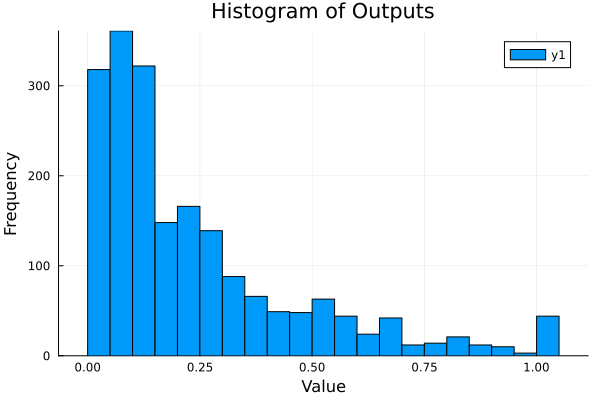

In [27]:
outputs = data[:, end]
histogram(outputs, 
    title="Histogram of Outputs",
    xlabel="Value",
    ylabel="Frequency"
)


In [28]:
using .Sampling
using .Preprocessing
using .Training
using .Output

In [29]:
# edges = [0.15, 0.4, 0.70, 1.0, 6.0]
# binned_vector = bin_to_multiclass(outputs, edges)
# # Stratified binarization logaritmic
# println("Original Data: ", outputs)
# println("Bin Edges: ", edges)
# println("Binned Vector (Bin Indices): ", binned_vector)

using Statistics

# using quantile, we obtain an equal distribution of samples per bin
raw_target = data[:, end]
edges = quantile(raw_target, range(0, 1, length=5))
edges[end] += 0.0001
println("Bin Edges: ", edges)

binned_vector = bin_to_multiclass(raw_target, edges)

counts = [count(x -> x == i, binned_vector) for i in 1:4]
println("Distribution of classes: ", counts)

Bin Edges: [0.0, 0.07, 0.15, 0.33, 1.0001]
Distribution of classes: [484, 468, 537, 505]


In [30]:
train_output_binned = binned_vector[train_idx,end]
val_output_binned = binned_vector[val_idx,end]
test_output_binned = binned_vector[test_idx, end]

199-element Vector{Int64}:
 3
 1
 4
 4
 3
 1
 1
 2
 3
 3
 ⋮
 1
 3
 2
 3
 1
 3
 4
 1
 1

Como resultado del procesamiento de los datos se ofrecen:

- Como datos de entrada: 
    - Sin reducir: train_input, val_input, test_input
    - Con PCA (0.95 of total variance, 33 features): pca_train, pca_val, pca_test
    - Con PCA (0.99 of total variance, 58 features): pca_train_99, pca_val_99, pca_test_99
- Como datos de salida:
    - Regression: train_output, val_output, test_output
    - Classification (applying bining): train_output_binned, val_output_binned, test_output_binned

## Training the models

Ofrecemos una alternativa a la separación de train y validation llamada "merge":
- Como datos de entrada: 
    - Sin reducir: train_input_merge, test_input
    - Con PCA (0.95 of total variance, 33 features): pca_train_merge, pca_test
    - Con PCA (0.99 of total variance, 58 features): pca_train_99_merge, pca_test_99
    - Con ICA: (2 features): ica_train_merge, ica_test
- Como datos de salida:
    - Regression: train_output_merge, test_output
    - Classification (applying bining): train_output_binned_merge, test_output_binned

In [31]:
train_input_merge = vcat(train_input, val_input)
pca_train_merge =  vcat(pca_train, pca_val)
pca_train_99_merge = vcat(pca_train_99, pca_val_99)
ica_train_merge = vcat(ica_train, ica_val)
train_output_merge = vcat(train_output, val_output)
train_output_binned_merge = vcat(train_output_binned, val_output_binned)

println("train_input_merge => size: ", size(train_input_merge))
println("pca_train_merge => size: ", size(pca_train_merge))
println("pca_train_99_merge => size: ", size(pca_train_99_merge))
println("ica_train_merge => size: ", size(ica_train_merge))
println("train_output_merge => length: ", length(train_output_merge))
println("train_output_binned_merge => length: ", length(train_output_binned_merge))


train_input_merge => size: (1795, 100)
pca_train_merge => size: (1795, 32)
pca_train_99_merge => size: (1795, 57)
ica_train_merge => size: (1795, 2)
train_output_merge => length: 1795
train_output_binned_merge => length: 1795


Here we do a training based on k-fold cross validation, checking different configurations of the classification models used in class.

The idea is to check what of those configurations present the best accuracy and standard deviation for further use afterwards

In [32]:

k_folds = 10

cv_indices = crossvalidation(train_output_binned_merge, k_folds)

println("Strategy: $k_folds-Fold Cross-Validation with $(length(cv_indices)) attributes.")

experiment_inputs = Dict(
    "Raw Attributes"   => Float32.(train_input_merge),
    "PCA (95% Var)"    => Float32.(pca_train_merge),
    "PCA (99% Var)"    => Float32.(pca_train_99_merge),
    "ICA (2 Comp)"     => Float32.(ica_train_merge)
)

current_targets = train_output_binned_merge

using Printf
using Flux
function log_result(approach, model, config, acc_mean, acc_std)
    @printf("%-15s | %-15s | %-35s | Acc: %.2f%% ± %.2f%%\n", 
            approach, model, config, acc_mean * 100, acc_std * 100)
end

println("\nINITIALIZING EXPERIMENTS...")
println("==================================================================================================")
println("Dataset         | Model           | Configuration                        | Result (CV Mean ± SD)")
println("--------------------------------------------------------------------------------------------------")

for (approach_name, inputs) in experiment_inputs
    
    dataset_tuple = (inputs, current_targets)

    # Artificial Neural Networks

    ann_topologies = [
        [8], [16], [32], [64],           
        [8, 8], [16, 16], [32, 32], [64, 64] 
    ]
    
    for topo in ann_topologies
        params = Dict(
            :topology => topo,
            :transferFunctions => fill(Flux.relu, length(topo)),
            :maxEpochs => 100, 
            :learningRate => 0.01,
            :showText => false,
            :validationRatio => 0.1 
        )
        
        try
            res = modelCrossValidation(:ANN, params, dataset_tuple, cv_indices)
            log_result(approach_name, "ANN", "Topo=$(string(topo))", res.accuracy[1], res.accuracy[2])
        catch e
            println("Error en ANN $topo: $e")
        end
    end

    # Support Vector Machines
    svm_configs = [
        Dict(:kernel => "LINEAR", :C => 0.1),
        Dict(:kernel => "LINEAR", :C => 1.0),
        Dict(:kernel => "LINEAR", :C => 10.0),

        Dict(:kernel => "RBF", :C => 1.0, :gamma => 0.01),
        Dict(:kernel => "RBF", :C => 1.0, :gamma => 0.1),
        Dict(:kernel => "RBF", :C => 10.0, :gamma => 0.01),
        Dict(:kernel => "RBF", :C => 100.0, :gamma => 0.001),

        Dict(:kernel => "POLY", :C => 1.0, :degree => Int32(2)) 
    ]

    for conf in svm_configs
        try
            res = modelCrossValidation(:SVC, conf, dataset_tuple, cv_indices)
            kernel_name = conf[:kernel]
            desc = "K=$(kernel_name), C=$(conf[:C])"
            
            if haskey(conf, :gamma) 
                desc *= ", g=$(conf[:gamma])" 
            end
            if haskey(conf, :degree) 
                desc *= ", d=$(conf[:degree])" 
            end
            
            log_result(approach_name, "SVM", desc, res.accuracy[1], res.accuracy[2])
        catch e
            println("Error en SVM $(conf): $e")
        end
    end

    # Decision Trees 
    dt_depths = [3, 5, 7, 9, 15, 20]
    
    for depth in dt_depths
        params = Dict(:max_depth => depth)
        try
            res = modelCrossValidation(:DecisionTreeClassifier, params, dataset_tuple, cv_indices)
            log_result(approach_name, "D.Tree", "MaxDepth=$depth", res.accuracy[1], res.accuracy[2])
        catch e
            println("Error en DT $depth: $e")
        end
    end


    #  k-Nearest Neighbors 
    knn_k_values = [1, 3, 5, 7, 11, 21]
    
    for k in knn_k_values
        params = Dict(:K => k)
        try
            res = modelCrossValidation(:KNeighborsClassifier, params, dataset_tuple, cv_indices)
            log_result(approach_name, "kNN", "K=$k", res.accuracy[1], res.accuracy[2])
        catch e
            println("Error en kNN $k: $e")
        end
    end
    
    println("--------------------------------------------------------------------------------------------------")
end

Strategy: 10-Fold Cross-Validation with 1795 attributes.

INITIALIZING EXPERIMENTS...
Dataset         | Model           | Configuration                        | Result (CV Mean ± SD)
--------------------------------------------------------------------------------------------------
Raw Attributes  | ANN             | Topo=[8]                            | Acc: 55.54% ± 2.72%
Raw Attributes  | ANN             | Topo=[16]                           | Acc: 55.66% ± 2.09%
Raw Attributes  | ANN             | Topo=[32]                           | Acc: 55.15% ± 3.11%
Raw Attributes  | ANN             | Topo=[64]                           | Acc: 55.55% ± 2.91%
Raw Attributes  | ANN             | Topo=[8, 8]                         | Acc: 55.82% ± 2.30%
Raw Attributes  | ANN             | Topo=[16, 16]                       | Acc: 55.94% ± 2.71%
Raw Attributes  | ANN             | Topo=[32, 32]                       | Acc: 55.52% ± 2.68%
Raw Attributes  | ANN             | Topo=[64, 64]           

After the cross validation, we have obtained the results of the different models with each configuration for each preprocessing strategy.
Here we are using the best for each preprocessing strategy with the whole training set.

In [69]:
# Raw
using MLJFlux

params = Dict(
    :topology => (16, 16),
    :transferFunctions => Flux.relu,
    :epochs => 100,
    :optimiser => Optimisers.Adam(0.01),
    :loss => Flux.mse,
    :batch_size => 32
)

best_ann_class_model = createModel(:ANN, params)
best_ann_class_machine = machine(best_ann_class_model, MLJ.table(train_input_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_ann_class_machine, rows=1:size(train_input_merge, 1), verbosity=0)

final_preds_ann_class = MLJ.predict(best_ann_class_machine, MLJ.table(test_input))
outputs_test_ann_class = string.(MLJ.mode.(final_preds_ann_class))
targets_test_ann_class = string.(test_output_binned)
classes = unique(vcat(outputs_test_ann_class, targets_test_ann_class))
println("Final ANN raw Test Results:")
printConfusionMatrix(outputs_test_ann_class, targets_test_ann_class, classes; weighted=false)
println("\n")

# PCA 95
params = Dict(
    :topology => (8, 8),
    :transferFunctions => Flux.relu,
    :epochs => 100,
    :optimiser => Optimisers.Adam(0.01),
    :loss => Flux.mse,
    :batch_size => 32
)

best_ann_class_model_95 = createModel(:ANN, params)
best_ann_class_machine_95 = machine(best_ann_class_model_95, MLJ.table(pca_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_ann_class_machine_95, rows=1:size(pca_train_merge, 1), verbosity=0)

final_preds_ann_class_95 = MLJ.predict(best_ann_class_machine_95, MLJ.table(pca_test))
outputs_test_ann_class_95 = string.(MLJ.mode.(final_preds_ann_class_95))
targets_test_ann_class_95 = string.(test_output_binned)
classes = unique(vcat(outputs_test_ann_class_95, targets_test_ann_class_95))
println("Final ANN 95 Test Results:")
printConfusionMatrix(outputs_test_ann_class_95, targets_test_ann_class_95, classes; weighted=false)
println("\n")

# PCA 99
params = Dict(
    :topology => (32, 32),
    :transferFunctions => Flux.relu,
    :epochs => 100,
    :optimiser => Optimisers.Adam(0.01),
    :loss => Flux.mse,
    :batch_size => 32
)

best_ann_class_model_99 = createModel(:ANN, params)
best_ann_class_machine_99 = machine(best_ann_class_model_99, MLJ.table(pca_train_99_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_ann_class_machine_99, rows=1:size(pca_train_99_merge, 1), verbosity=0)

final_preds_ann_class_99 = MLJ.predict(best_ann_class_machine_99, MLJ.table(pca_test_99))
outputs_test_ann_class_99 = string.(MLJ.mode.(final_preds_ann_class_99))
targets_test_ann_class_99 = string.(test_output_binned)
classes = unique(vcat(outputs_test_ann_class_99, targets_test_ann_class_99))
println("Final ANN 99 Test Results:")
printConfusionMatrix(outputs_test_ann_class_99, targets_test_ann_class_99, classes; weighted=false)
println("\n")

# ICA
params = Dict(
    :topology => (64, 64),
    :transferFunctions => Flux.relu,
    :epochs => 100,
    :optimiser => Optimisers.Adam(0.01),
    :loss => Flux.mse,
    :batch_size => 32
)

best_ann_class_model_ica = createModel(:ANN, params)
best_ann_class_machine_ica = machine(best_ann_class_model_ica, MLJ.table(ica_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_ann_class_machine_ica, rows=1:size(ica_train_merge, 1), verbosity=0)

final_preds_ann_class_ica = MLJ.predict(best_ann_class_machine_ica, MLJ.table(ica_test))
outputs_test_ann_class_ica = string.(MLJ.mode.(final_preds_ann_class_ica))
targets_test_ann_class_ica = string.(test_output_binned)
classes = unique(vcat(outputs_test_ann_class_ica, targets_test_ann_class_ica))
println("Final ANN ICA Test Results:")
printConfusionMatrix(outputs_test_ann_class_ica, targets_test_ann_class_ica, classes; weighted=false)
println("\n")


Final ANN raw Test Results:
Macro Metrics:
Accuracy: 0.6030150753768844
Error Rate: 0.39698492462311563
Sensitivity (Recall): 0.5974739278712292
Specificity: 0.8678540270569368
Positive Predictive Value (Precision): 0.595032489740082
Negative Predictive Value (Precision): 0.8700074429541457
F-score: 0.5907520925198182
Confusion Matrix:
[18 12 0 9; 9 47 1 1; 1 0 35 10; 20 9 7 20]


Final ANN 95 Test Results:
Macro Metrics:
Accuracy: 0.5678391959798995
Error Rate: 0.4321608040201005
Sensitivity (Recall): 0.5637373620881867
Specificity: 0.8558078300940473
Positive Predictive Value (Precision): 0.5803851984444977
Negative Predictive Value (Precision): 0.8544060581063307
F-score: 0.5681477923895871
Confusion Matrix:
[38 16 3 1; 7 20 10 2; 8 13 28 7; 0 0 19 27]


Final ANN 99 Test Results:
Macro Metrics:
Accuracy: 0.5577889447236181
Error Rate: 0.44221105527638194
Sensitivity (Recall): 0.5740378437155049
Specificity: 0.8549676934454782
Positive Predictive Value (Precision): 0.559628060263653

In [82]:
# SVM Raw
best_svm_class_model = createModel(:SVPC, Dict(:kernel => "RBF", :C => 1.0, :gamma => 0.01))
best_svm_class_machine = machine(best_svm_class_model, MLJ.table(train_input_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_svm_class_machine, rows=1:size(train_input_merge, 1), verbosity=0)
final_preds_svm_class = MLJ.predict(best_svm_class_machine, MLJ.table(test_input))
outputs_test_svm_class = string.(MLJ.mode.(MLJ.unwrap.(final_preds_svm_class)))
targets_test_svm_class = string.(test_output_binned)
classes = unique(vcat(outputs_test_svm_class, targets_test_svm_class))
println("Final SVM raw Test Results:")
printConfusionMatrix(outputs_test_svm_class, targets_test_svm_class, classes; weighted=false)
println("\n")

# SVM PCA 95
best_svm_class_model_95 = createModel(:SVPC, Dict(:kernel => "RBF", :C => 100.0, :gamma => 0.001))
best_svm_class_machine_95 = machine(best_svm_class_model_95, MLJ.table(pca_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_svm_class_machine_95, rows=1:size(pca_train_merge, 1), verbosity=0)
final_preds_svm_class_95 = MLJ.predict(best_svm_class_machine_95, MLJ.table(pca_test))
outputs_test_svm_class_95 = string.(MLJ.mode.(MLJ.unwrap.(final_preds_svm_class_95)))
targets_test_svm_class_95 = string.(test_output_binned)
classes = unique(vcat(outputs_test_svm_class_95, targets_test_svm_class_95))
println("Final SVM 95 Test Results:")
printConfusionMatrix(outputs_test_svm_class_95, targets_test_svm_class_95, classes; weighted=false)
println("\n")

# SVM PCA 99
best_svm_class_model_99 = createModel(:SVPC, Dict(:kernel => "RBF", :C => 100.0, :gamma => 0.001))
best_svm_class_machine_99 = machine(best_svm_class_model_99, MLJ.table(pca_train_99_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_svm_class_machine_99, rows=1:size(pca_train_99_merge, 1), verbosity=0)
final_preds_svm_class_99 = MLJ.predict(best_svm_class_machine_99, MLJ.table(pca_test_99))
outputs_test_svm_class_99 = string.(MLJ.mode.(MLJ.unwrap.(final_preds_svm_class_99)))
targets_test_svm_class_99 = string.(test_output_binned)
classes = unique(vcat(outputs_test_svm_class_99, targets_test_svm_class_99))
println("Final SVM 95 Test Results:")
printConfusionMatrix(outputs_test_svm_class_99, targets_test_svm_class_99, classes; weighted=false)
println("\n")

# SVM ICA
best_svm_class_model_ica = createModel(:SVPC, Dict(:kernel => "RBF", :C => 1.0, :gamma => 0.1))
best_svm_class_machine_ica = machine(best_svm_class_model_ica, MLJ.table(ica_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_svm_class_machine_ica, rows=1:size(ica_train_merge, 1), verbosity=0)
final_preds_svm_class_ica = MLJ.predict(best_svm_class_machine_ica, MLJ.table(ica_test))
outputs_test_svm_class_ica = string.(MLJ.mode.(MLJ.unwrap.(final_preds_svm_class_ica)))
targets_test_svm_class_ica = string.(test_output_binned)
classes = unique(vcat(outputs_test_svm_class_ica, targets_test_svm_class_ica))
println("Final SVM ICA Test Results:")
printConfusionMatrix(outputs_test_svm_class_ica, targets_test_svm_class_ica, classes; weighted=false)
println("\n")


Final SVM raw Test Results:
Macro Metrics:
Accuracy: 0.6231155778894473
Error Rate: 0.37688442211055273
Sensitivity (Recall): 0.6167584133757298
Specificity: 0.8743563502187564
Positive Predictive Value (Precision): 0.6052543644298963
Negative Predictive Value (Precision): 0.8756366646342048
F-score: 0.6092723889963415
Confusion Matrix:
[17 10 2 10; 8 44 1 5; 1 0 38 7; 14 6 11 25]


Final SVM 95 Test Results:
Macro Metrics:
Accuracy: 0.6130653266331658
Error Rate: 0.3869346733668342
Sensitivity (Recall): 0.6050673152434772
Specificity: 0.8717954233657457
Positive Predictive Value (Precision): 0.6016775569877073
Negative Predictive Value (Precision): 0.8715850127859268
F-score: 0.6019314590824889
Confusion Matrix:
[16 9 2 12; 12 43 1 2; 1 0 37 8; 16 5 9 26]


Final SVM 95 Test Results:
Macro Metrics:
Accuracy: 0.6130653266331658
Error Rate: 0.3869346733668342
Sensitivity (Recall): 0.6060427890450379
Specificity: 0.8717706254686073
Positive Predictive Value (Precision): 0.603534004274458

In [79]:
# Decision Tree Raw
best_dt_class_model = createModel(:DecisionTreeClassifier, Dict(:max_depth => 5))
best_dt_class_machine = machine(best_dt_class_model, MLJ.table(train_input_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_dt_class_machine, rows=1:size(train_input_merge, 1), verbosity=0)
final_preds_dt_class = MLJ.predict(best_dt_class_machine, MLJ.table(test_input))
outputs_test_dt_class = string.(MLJ.mode.(final_preds_dt_class))
targets_test_dt_class = string.(test_output_binned)
classes = unique(vcat(outputs_test_dt_class, targets_test_dt_class))
println("Final Decision Tree raw Test Results:")
printConfusionMatrix(outputs_test_dt_class, targets_test_dt_class, classes; weighted=false)
println("\n")

# Decision Tree PCA 95
best_dt_class_model_95 = createModel(:DecisionTreeClassifier, Dict(:max_depth => 5))
best_dt_class_machine_95 = machine(best_dt_class_model_95, MLJ.table(pca_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_dt_class_machine_95, rows=1:size(pca_train_merge, 1), verbosity=0)
final_preds_dt_class_95 = MLJ.predict(best_dt_class_machine_95, MLJ.table(pca_test))
outputs_test_dt_class_95 = string.(MLJ.mode.(final_preds_dt_class_95))
targets_test_dt_class_95 = string.(test_output_binned)
classes = unique(vcat(outputs_test_dt_class_95, targets_test_dt_class_95))
println("Final Decision Tree 95 Test Results:")
printConfusionMatrix(outputs_test_dt_class_95, targets_test_dt_class_95, classes; weighted=false)
println("\n")

# Decision Tree PCA 99
best_dt_class_model_99 = createModel(:DecisionTreeClassifier, Dict(:max_depth => 5))
best_dt_class_machine_99 = machine(best_dt_class_model_99, MLJ.table(pca_train_99_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_dt_class_machine_99, rows=1:size(pca_train_99_merge, 1), verbosity=0)
final_preds_dt_class_99 = MLJ.predict(best_dt_class_machine_99, MLJ.table(pca_test_99))
outputs_test_dt_class_99 = string.(MLJ.mode.(final_preds_dt_class_99))
targets_test_dt_class_99 = string.(test_output_binned)
classes = unique(vcat(outputs_test_dt_class_99, targets_test_dt_class_99))
println("Final Decision Tree 99 Test Results:")
printConfusionMatrix(outputs_test_dt_class_99, targets_test_dt_class_99, classes; weighted=false)
println("\n")

# Decision Tree ICA
best_dt_class_model_ica = createModel(:DecisionTreeClassifier, Dict(:max_depth => 5))
best_dt_class_machine_ica = machine(best_dt_class_model_ica, MLJ.table(ica_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_dt_class_machine_ica, rows=1:size(ica_train_merge, 1), verbosity=0)
final_preds_dt_class_ica = MLJ.predict(best_dt_class_machine_ica, MLJ.table(ica_test))
outputs_test_dt_class_ica = string.(MLJ.mode.(final_preds_dt_class_ica))
targets_test_dt_class_ica = string.(test_output_binned)
classes = unique(vcat(outputs_test_dt_class_ica, targets_test_dt_class_ica))
println("Final Decision Tree ICA Test Results:")
printConfusionMatrix(outputs_test_dt_class_ica, targets_test_dt_class_ica, classes; weighted=false)
println("\n")


Final Decision Tree raw Test Results:
Macro Metrics:
Accuracy: 0.542713567839196
Error Rate: 0.457286432160804
Sensitivity (Recall): 0.526356842183304
Specificity: 0.8477609869271321
Positive Predictive Value (Precision): 0.5564322063136105
Negative Predictive Value (Precision): 0.8466561659398646
F-score: 0.5364204721963343
Confusion Matrix:
[12 14 11 2; 16 41 0 1; 19 7 27 3; 1 0 17 28]


Final Decision Tree 95 Test Results:
Macro Metrics:
Accuracy: 0.46733668341708545
Error Rate: 0.5326633165829145
Sensitivity (Recall): 0.46682668281243994
Specificity: 0.8224226202284713
Positive Predictive Value (Precision): 0.4645422824302135
Negative Predictive Value (Precision): 0.8226278809977269
F-score: 0.46328034991828093
Confusion Matrix:
[37 6 0 15; 12 14 13 17; 0 19 25 2; 9 9 4 17]


Final Decision Tree 99 Test Results:
Macro Metrics:
Accuracy: 0.46733668341708545
Error Rate: 0.5326633165829145
Sensitivity (Recall): 0.4677971797068499
Specificity: 0.8226550610076893
Positive Predictive Val

In [76]:
# kNN Raw
best_knn_class_model = createModel(:KNeighborsClassifier, Dict(:K => 21))
best_knn_class_machine = machine(best_knn_class_model, MLJ.table(train_input_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_knn_class_machine, rows=1:size(train_input_merge, 1), verbosity=0)
final_preds_knn_class = MLJ.predict(best_knn_class_machine, MLJ.table(test_input))
outputs_test_knn_class = string.(MLJ.mode.(final_preds_knn_class))
targets_test_knn_class = string.(test_output_binned)
classes = unique(vcat(outputs_test_knn_class, targets_test_knn_class))
println("Final kNN raw Test Results:")
printConfusionMatrix(outputs_test_knn_class, targets_test_knn_class, classes; weighted=false)
println("\n")

# kNN PCA 95
best_knn_class_model_95 = createModel(:KNeighborsClassifier, Dict(:K => 21))
best_knn_class_machine_95 = machine(best_knn_class_model_95, MLJ.table(pca_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_knn_class_machine_95, rows=1:size(pca_train_merge, 1), verbosity=0)
final_preds_knn_class_95 = MLJ.predict(best_knn_class_machine_95, MLJ.table(pca_test))
outputs_test_knn_class_95 = string.(MLJ.mode.(final_preds_knn_class_95))
targets_test_knn_class_95 = string.(test_output_binned)
classes = unique(vcat(outputs_test_knn_class_95, targets_test_knn_class_95))
println("Final kNN 95 Test Results:")
printConfusionMatrix(outputs_test_knn_class_95, targets_test_knn_class_95, classes; weighted=false)
println("\n")

# kNN PCA 99
best_knn_class_model_99 = createModel(:KNeighborsClassifier, Dict(:K => 5))
best_knn_class_machine_99 = machine(best_knn_class_model_99, MLJ.table(pca_train_99_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_knn_class_machine_99, rows=1:size(pca_train_99_merge, 1), verbosity=0)
final_preds_knn_class_99 = MLJ.predict(best_knn_class_machine_99, MLJ.table(pca_test_99))
outputs_test_knn_class_99 = string.(MLJ.mode.(final_preds_knn_class_99))
targets_test_knn_class_99 = string.(test_output_binned)
classes = unique(vcat(outputs_test_knn_class_99, targets_test_knn_class_99))
println("Final kNN 99 Test Results:")
printConfusionMatrix(outputs_test_knn_class_99, targets_test_knn_class_99, classes; weighted=false)
println("\n")

# kNN ICA
best_knn_class_model_ica = createModel(:KNeighborsClassifier, Dict(:K => 21))
best_knn_class_machine_ica = machine(best_knn_class_model_ica, MLJ.table(ica_train_merge), categorical(train_output_binned_merge))
MLJ.fit!(best_knn_class_machine_ica, rows=1:size(ica_train_merge, 1), verbosity=0)
final_preds_knn_class_ica = MLJ.predict(best_knn_class_machine_ica, MLJ.table(ica_test))
outputs_test_knn_class_ica = string.(MLJ.mode.(final_preds_knn_class_ica))
targets_test_knn_class_ica = string.(test_output_binned)
classes = unique(vcat(outputs_test_knn_class_ica, targets_test_knn_class_ica))
println("Final kNN ICA Test Results:")
printConfusionMatrix(outputs_test_knn_class_ica, targets_test_knn_class_ica, classes; weighted=false)
println("\n")


Final kNN raw Test Results:
Macro Metrics:
Accuracy: 0.5527638190954773
Error Rate: 0.44723618090452266
Sensitivity (Recall): 0.5477678399811083
Specificity: 0.8524317544244797
Positive Predictive Value (Precision): 0.5477984848016964
Negative Predictive Value (Precision): 0.8526453809915298
F-score: 0.5423419782727554
Confusion Matrix:
[16 12 8 3; 13 42 1 2; 22 6 19 9; 2 0 11 33]


Final kNN 95 Test Results:
Macro Metrics:
Accuracy: 0.5628140703517588
Error Rate: 0.4371859296482412
Sensitivity (Recall): 0.5607472705954715
Specificity: 0.8557921019670081
Positive Predictive Value (Precision): 0.5634104199893674
Negative Predictive Value (Precision): 0.8552650668859065
F-score: 0.5567972268249789
Confusion Matrix:
[19 9 8 3; 15 41 0 2; 19 7 21 9; 2 0 13 31]


Final kNN 99 Test Results:
Macro Metrics:
Accuracy: 0.592964824120603
Error Rate: 0.40703517587939697
Sensitivity (Recall): 0.5846065634765034
Specificity: 0.8649385723267137
Positive Predictive Value (Precision): 0.586563691838291

And now, we are plotting the confussion matrix for the best models, to see which results are more interesting

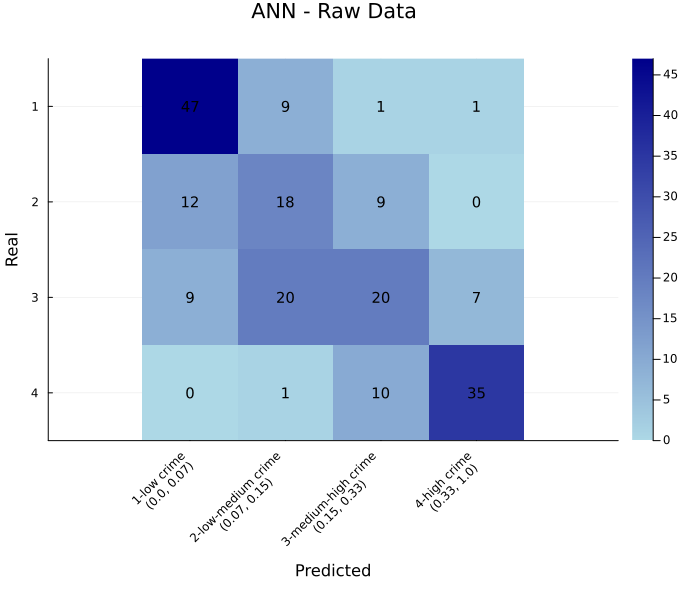

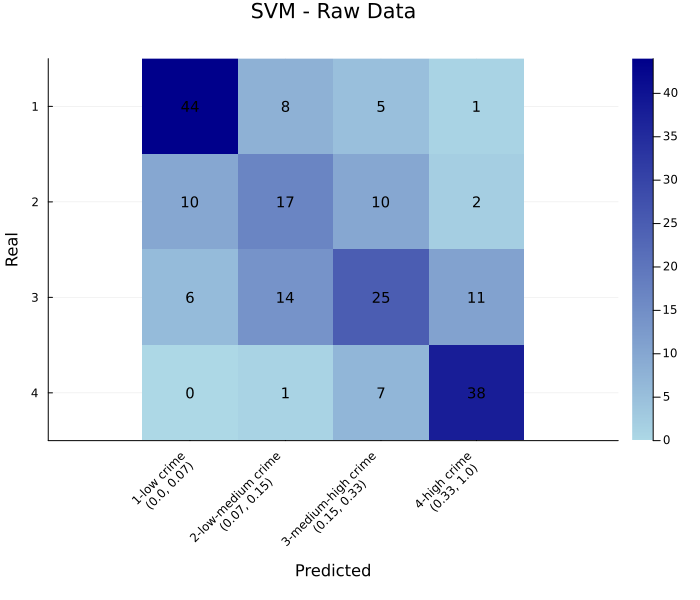

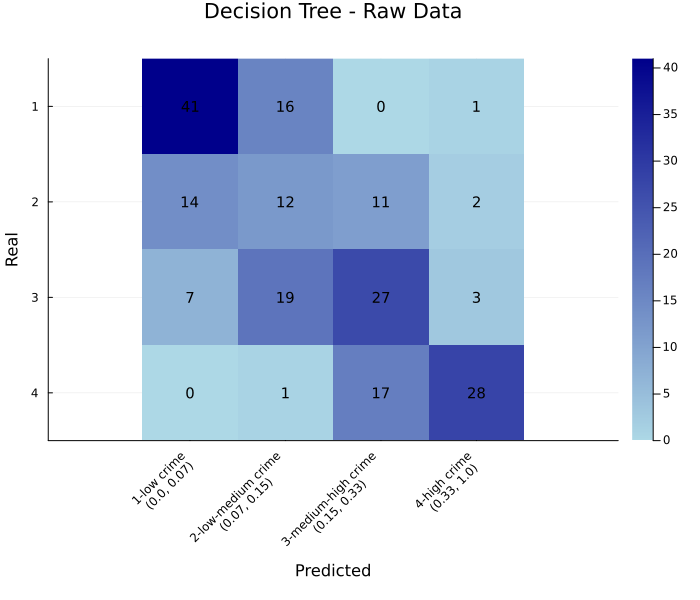

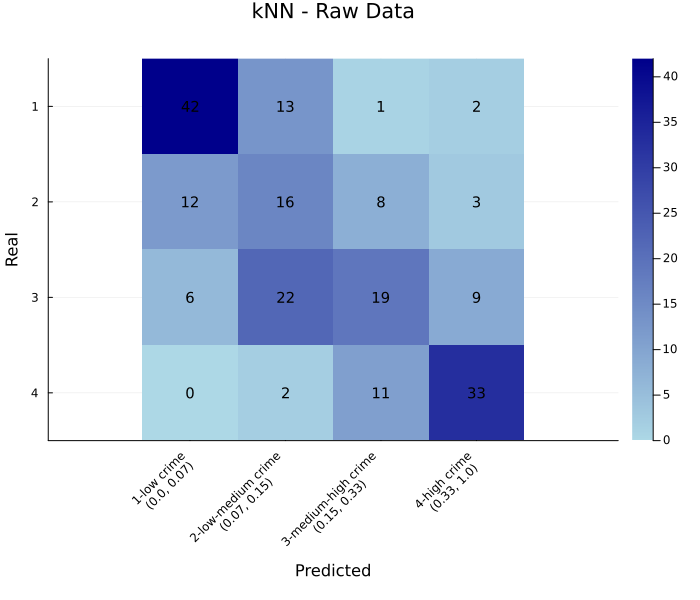

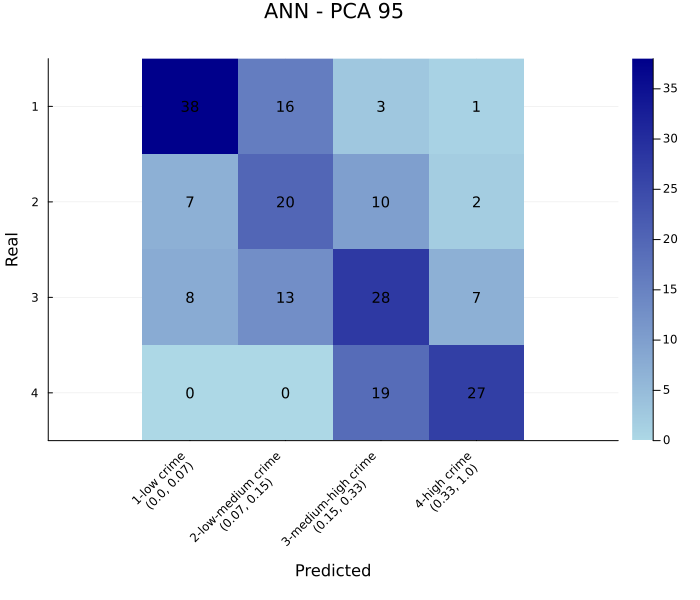

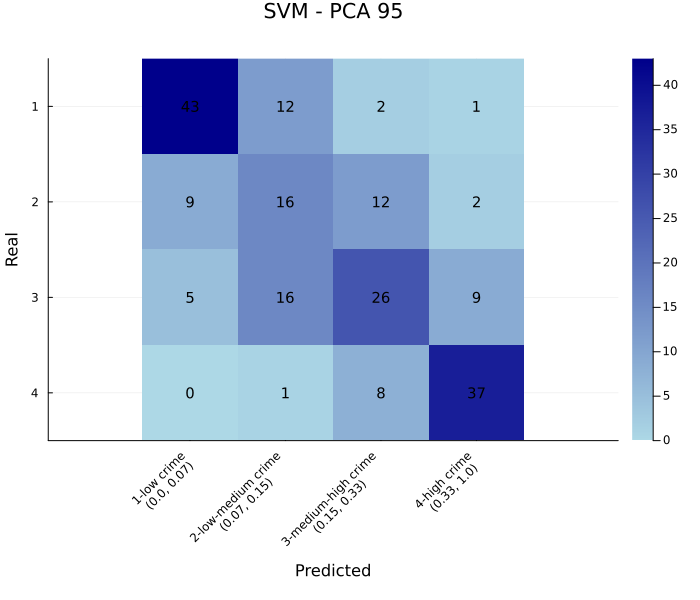

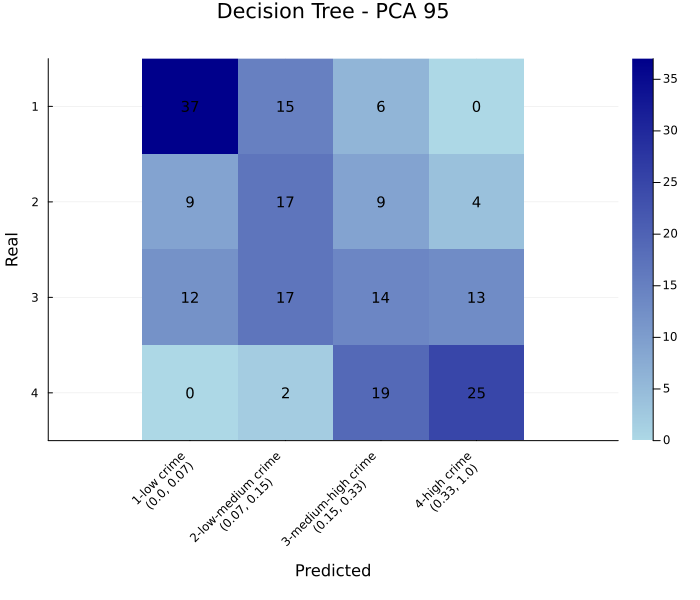

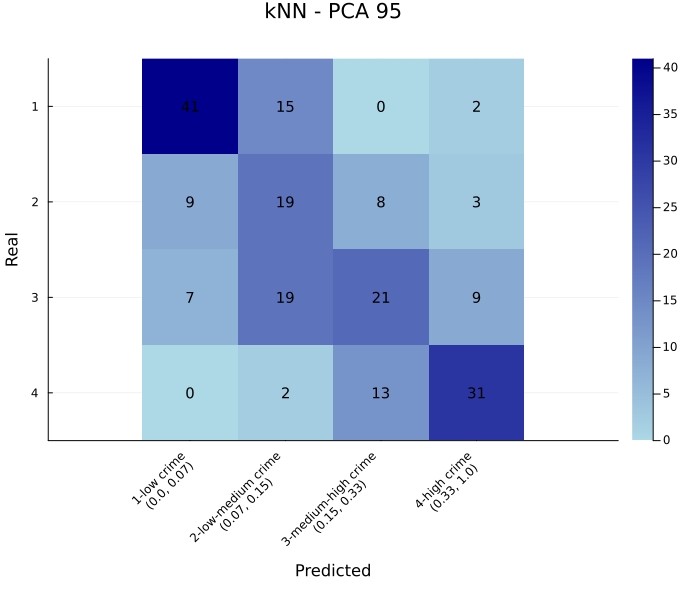

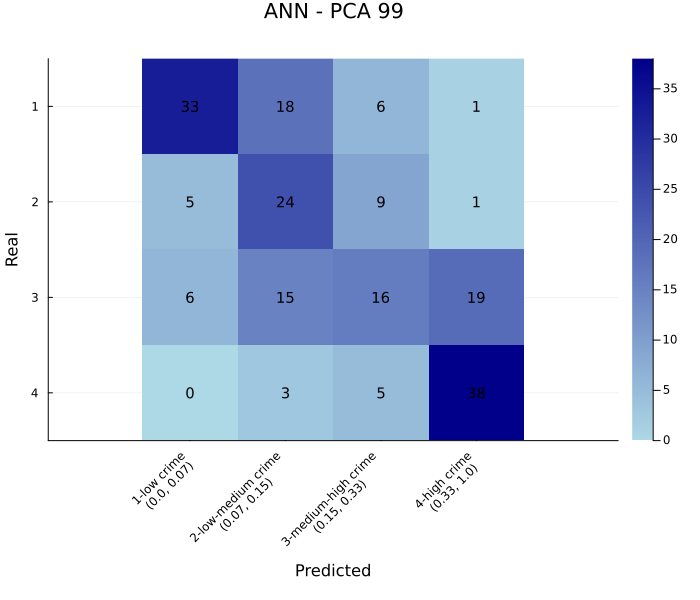

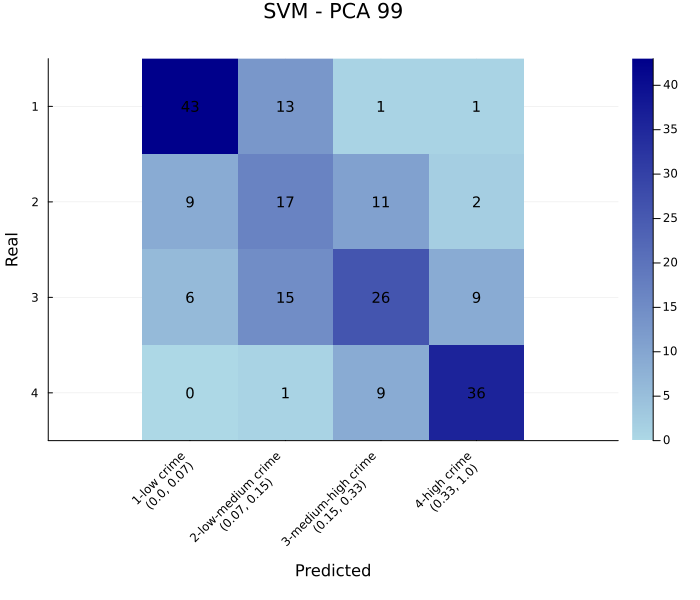

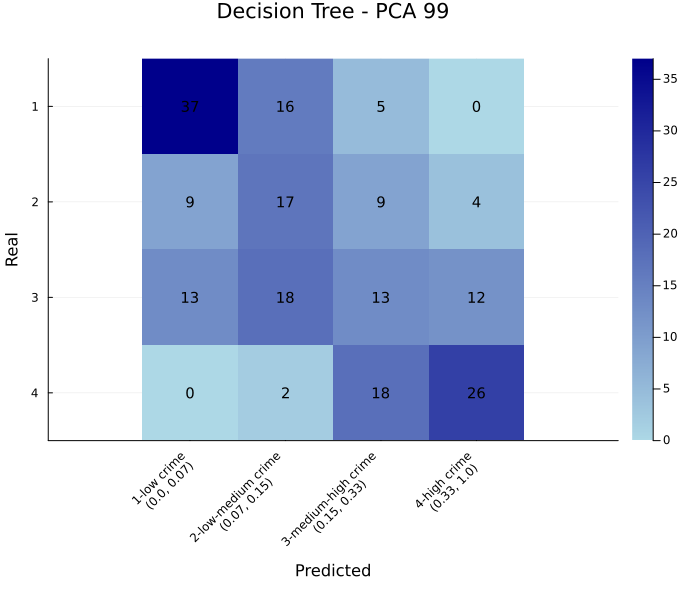

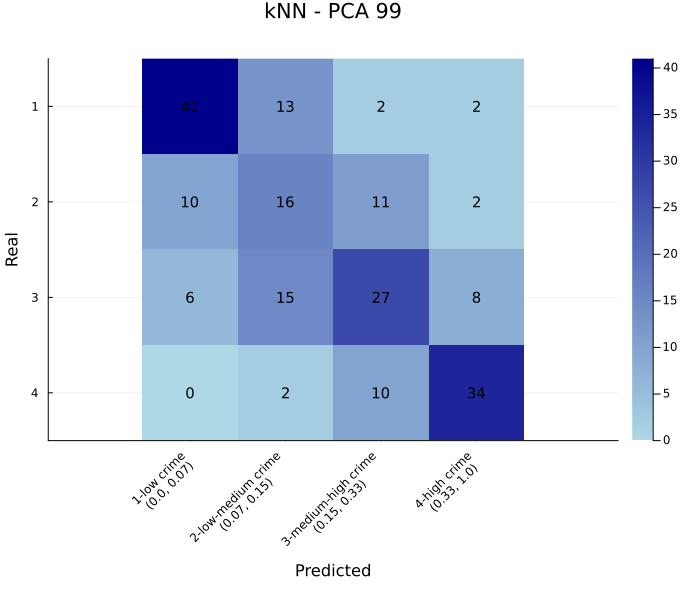

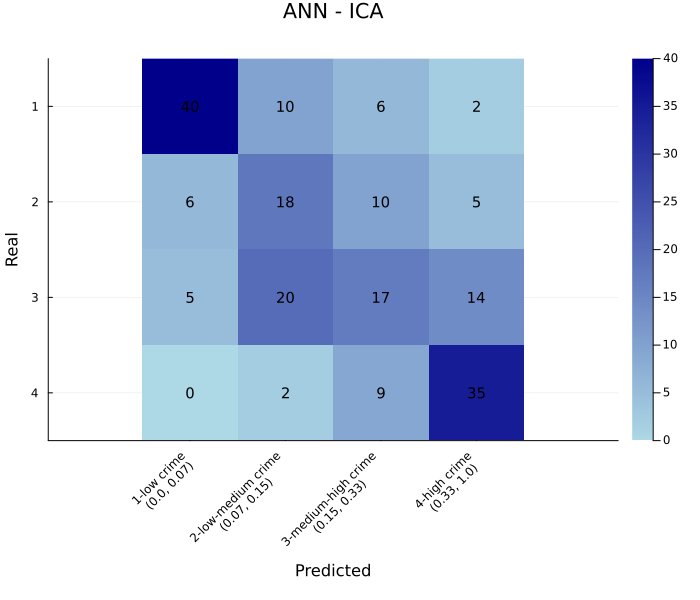

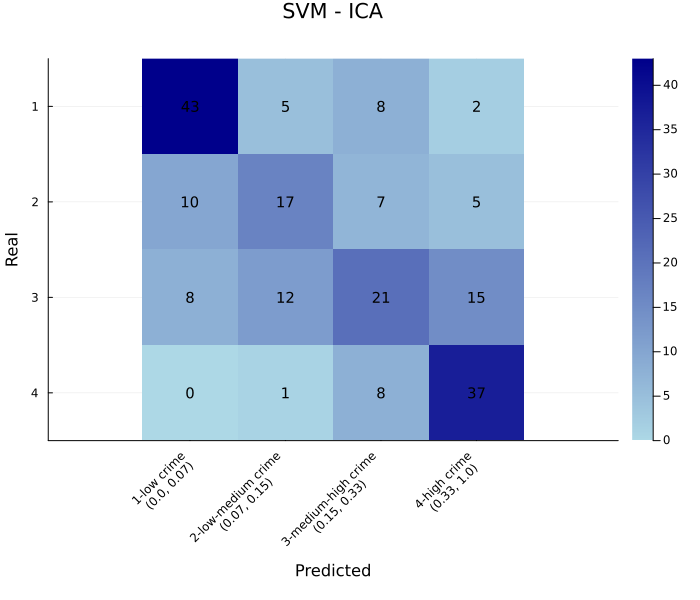

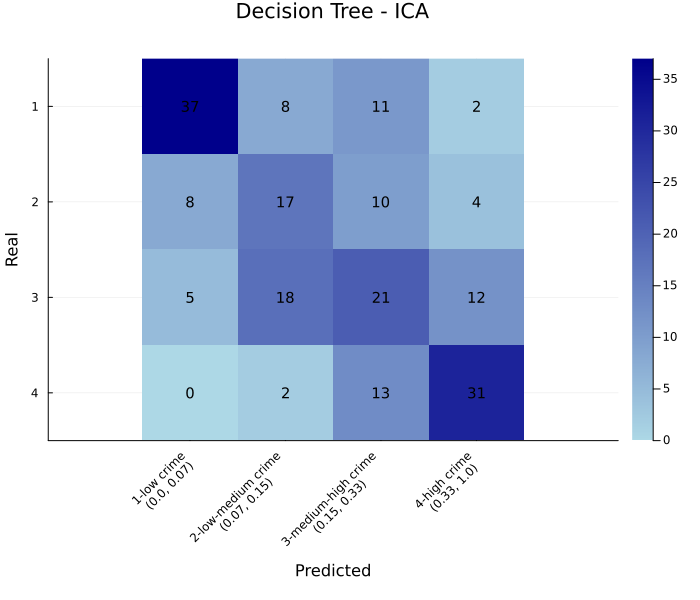

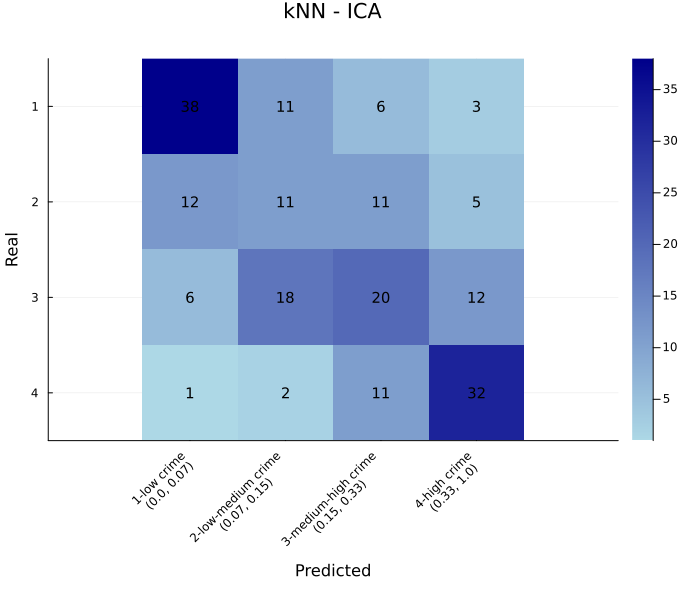

In [83]:
using Plots
gr()

# function to plot and save confusion matrix
function plotConfusionMatrix(outputs, targets, classes, title_str)

    sorted_classes = try
        sort(classes, by = x -> parse(Float64, string(x)))
    catch
        sort(classes)
    end

    n = length(sorted_classes)
    class_map = Dict(c => i for (i, c) in enumerate(sorted_classes))
    matrix = zeros(Int, n, n)

    for (pred, real) in zip(outputs, targets)
        if haskey(class_map, pred) && haskey(class_map, real)
            r = class_map[real]
            c = class_map[pred]
            matrix[r, c] += 1
        end
    end

    coords = 1:n

    annotations = [(j, i, text(string(matrix[i, j]), 10, :black, :center, :center)) for i in 1:n, j in 1:n]
    #[0.0, 0.07, 0.15, 0.33, 1.0001] <- this were the ranges obtained before for equal distribution
    display_labels = ["1-low crime \n(0.0, 0.07)", "2-low-medium crime \n(0.07, 0.15)", "3-medium-high crime \n(0.15, 0.33)", "4-high crime \n(0.33, 1.0)"]

    p = heatmap(
        coords,
        coords,
        #classes,
        #classes,
        matrix,
        color = :blues,
        aspect_ratio = 1,
        xrotation = 45,
        yflip = true,
        xlabel = "Predicted",
        ylabel = "Real",
        title = title_str,
        annotations = vec(annotations),
        xticks = (coords, display_labels),
        yticks = (coords, sorted_classes),
        size = (700, 600)
    )
    
    folder_name = "confussionMatrixes"

    if !isdir(folder_name)
        mkdir(folder_name)
        println("Carpeta creada: $folder_name")
    end
    safe_filename = replace(title_str, " " => "_", r"[^\w\-]" => "") 
    file_path = joinpath(folder_name, "$safe_filename.png")

    savefig(p, file_path)
    #println("Saved: $file_path")

    display(p)
end

# RAW
plotConfusionMatrix(outputs_test_ann_class,  targets_test_ann_class,  classes, "ANN - Raw Data")
plotConfusionMatrix(outputs_test_svm_class,  targets_test_svm_class,  classes, "SVM - Raw Data")
plotConfusionMatrix(outputs_test_dt_class,   targets_test_dt_class,   classes, "Decision Tree - Raw Data")
plotConfusionMatrix(outputs_test_knn_class,  targets_test_knn_class,  classes, "kNN - Raw Data")

# PCA 95
plotConfusionMatrix(outputs_test_ann_class_95,  targets_test_ann_class_95,  classes, "ANN - PCA 95")
plotConfusionMatrix(outputs_test_svm_class_95,  targets_test_svm_class_95,  classes, "SVM - PCA 95")
plotConfusionMatrix(outputs_test_dt_class_95,   targets_test_dt_class_95,   classes, "Decision Tree - PCA 95")
plotConfusionMatrix(outputs_test_knn_class_95,  targets_test_knn_class_95,  classes, "kNN - PCA 95")

# PCA 99
plotConfusionMatrix(outputs_test_ann_class_99,  targets_test_ann_class_99,  classes, "ANN - PCA 99")
plotConfusionMatrix(outputs_test_svm_class_99,  targets_test_svm_class_99,  classes, "SVM - PCA 99")
plotConfusionMatrix(outputs_test_dt_class_99,   targets_test_dt_class_99,   classes, "Decision Tree - PCA 99")
plotConfusionMatrix(outputs_test_knn_class_99,  targets_test_knn_class_99,  classes, "kNN - PCA 99")

# ICA
plotConfusionMatrix(outputs_test_ann_class_ica,  targets_test_ann_class_ica,  classes, "ANN - ICA")
plotConfusionMatrix(outputs_test_svm_class_ica,  targets_test_svm_class_ica,  classes, "SVM - ICA")
plotConfusionMatrix(outputs_test_dt_class_ica,   targets_test_dt_class_ica,   classes, "Decision Tree - ICA")
plotConfusionMatrix(outputs_test_knn_class_ica,  targets_test_knn_class_ica,  classes, "kNN - ICA")


This is an accuracy comparison for the aforementioned models

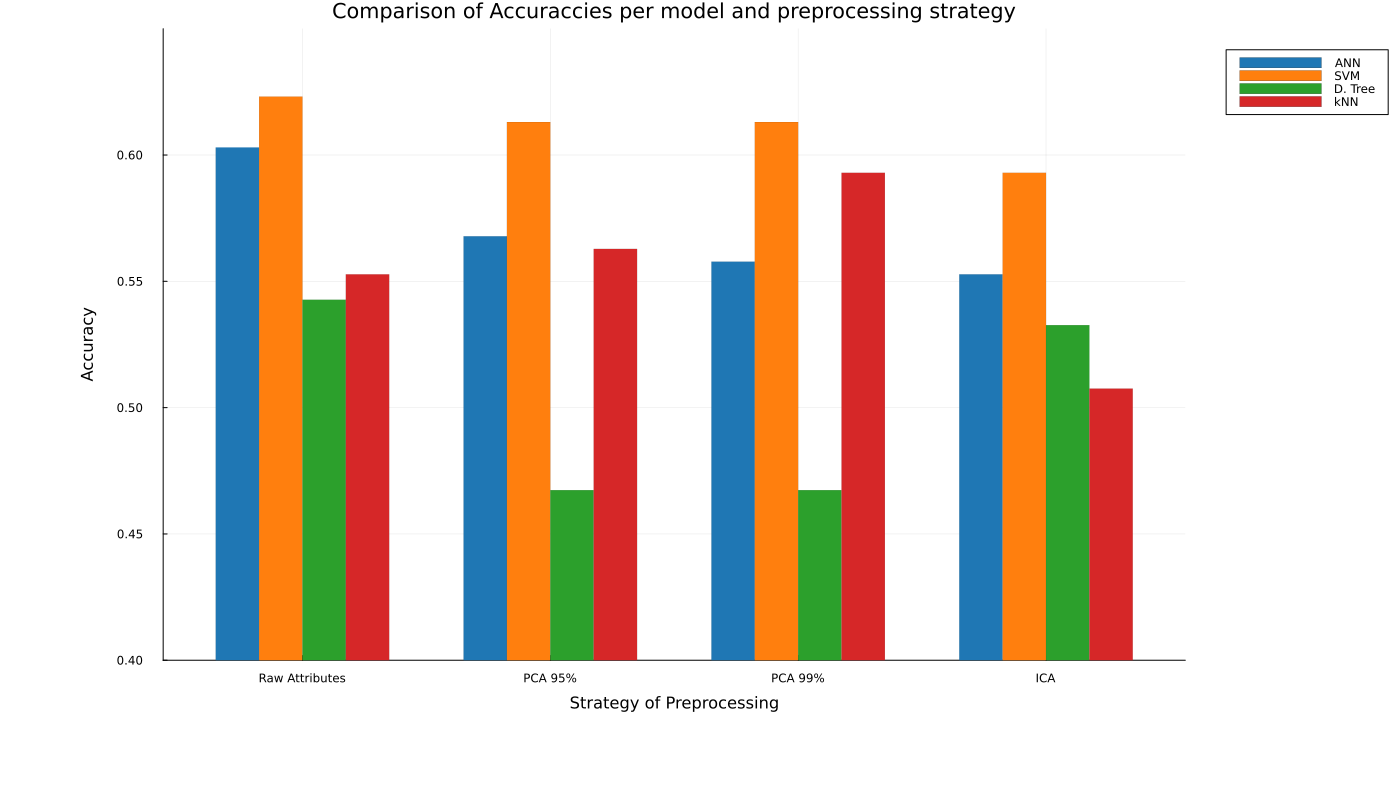

In [97]:
using StatsPlots
using Plots.Measures
using Statistics

# function that plots accuracy comparison, receiving a dict of preprocessing strategies and their respective model outputs and targets
function plotAccuracyComparison(data_to_plot)
    dataset_names = [s[1] for s in data_to_plot]

    first_set_models = data_to_plot[1][2] 
    model_names = [m[1] for m in first_set_models]
    n_datasets = length(dataset_names)
    n_models = length(model_names)

    acc_matrix = zeros(Float64, n_datasets, n_models)

    for (i, (d_name, models)) in enumerate(data_to_plot)
        for (j, (m_name, preds, targets)) in enumerate(models)

            accuracy = mean(string.(preds) .== string.(targets))
            acc_matrix[i, j] = accuracy
        end
    end


    labels = reshape(model_names, 1, n_models) 

    p = groupedbar(
        dataset_names,
        acc_matrix,
        label = labels,
        bar_width = 0.7,
        lw = 0,
        
        title = "Comparison of Accuraccies per model and preprocessing strategy",
        ylabel = "Accuracy",
        xlabel = "Strategy of Preprocessing",
        ylims = (0.4, 0.65),
        legend = :outertopright,
        palette = :tab10,
        left_margin = 25mm,    # Espacio para el YLABEL
        bottom_margin = 25mm,  # Espacio para el XLABEL
        size = (1400, 800)
    )

    folder_name = "comparison_plots"
    if !isdir(folder_name); mkdir(folder_name); end
    
    save_path = joinpath(folder_name, "accuracy_comparison.png")
    savefig(p, save_path)
    #println("Saved in: $save_path")
    
    display(p)
end


data_to_plot = [
    # RAW
    ("Raw Attributes", [
        ("ANN",   outputs_test_ann_class,      targets_test_ann_class),
        ("SVM",   outputs_test_svm_class,      targets_test_svm_class),
        ("D. Tree", outputs_test_dt_class,     targets_test_dt_class),
        ("kNN",   outputs_test_knn_class,      targets_test_knn_class)
    ]),

    # PCA 95
    ("PCA 95%", [
        ("ANN",   outputs_test_ann_class_95,   targets_test_ann_class_95),
        ("SVM",   outputs_test_svm_class_95,   targets_test_svm_class_95),
        ("D. Tree", outputs_test_dt_class_95,  targets_test_dt_class_95),
        ("kNN",   outputs_test_knn_class_95,   targets_test_knn_class_95)
    ]),

    # PCA 99
    ("PCA 99%", [
        ("ANN",   outputs_test_ann_class_99,   targets_test_ann_class_99),
        ("SVM",   outputs_test_svm_class_99,   targets_test_svm_class_99),
        ("D. Tree", outputs_test_dt_class_99,  targets_test_dt_class_99),
        ("kNN",   outputs_test_knn_class_99,   targets_test_knn_class_99)
    ]),

    # ICA
    ("ICA", [
        ("ANN",   outputs_test_ann_class_ica,  targets_test_ann_class_ica),
        ("SVM",   outputs_test_svm_class_ica,  targets_test_svm_class_ica),
        ("D. Tree", outputs_test_dt_class_ica, targets_test_dt_class_ica),
        ("kNN",   outputs_test_knn_class_ica,  targets_test_knn_class_ica)
    ])
]

# Ejecutar la función
plotAccuracyComparison(data_to_plot)

Now, we do the same as in classification but for regression. To do so, instead of the accuracy, we are checking the RMSE (or root mean squared error).

In [39]:
# If we want to use regression, we must change the models and load this versions instead
EpsilonSVR = @load EpsilonSVR pkg=LIBSVM verbosity=0
DTRegressor = @load DecisionTreeRegressor pkg=DecisionTree verbosity=0
KNNRegressor = @load KNNRegressor pkg=NearestNeighborModels verbosity=0
NeuralNetworkRegressor = @load NeuralNetworkRegressor pkg=MLJFlux verbosity=0



MLJFlux.NeuralNetworkRegressor

In [40]:
current_targets_reg = Float32.(train_output_merge)
k_folds = 10
cv_indices_reg = crossvalidation(length(train_output_merge), k_folds)

experiment_inputs = Dict(
    "Raw Attributes"   => Float32.(train_input_merge),
    "PCA (95% Var)"    => Float32.(pca_train_merge),
    "PCA (99% Var)"    => Float32.(pca_train_99_merge),
    "ICA (2 Comp)"     => Float32.(ica_train_merge)
)



Dict{String, Matrix{Float32}} with 4 entries:
  "Raw Attributes" => [0.0 0.45 … 0.15 0.0; 0.01 0.09 … 0.06 0.0; … ; 0.09 0.28…
  "PCA (99% Var)"  => [-1.13421 0.454608 … 0.00157066 -0.00344026; 1.7918 -0.90…
  "ICA (2 Comp)"   => [0.276148 1.18458; -0.64568 -1.91704; … ; -0.736846 -0.66…
  "PCA (95% Var)"  => [-1.13421 0.454608 … 0.234715 0.0729741; 1.7918 -0.904808…

In [49]:
using Printf
using MLJFlux
using LIBSVM    # Gave me errors without this

println("\nINITIALIZING EXPERIMENTS...")
println("==================================================================================================")
println("Dataset         | Model           | Configuration                        | Result (RMSE ± SD)")
println("--------------------------------------------------------------------------------------------------")
for (approach_name, inputs) in experiment_inputs
    
    # ANN or Neural Network Regressor
    ann_topologies = [(8,), (16,), (32,), (64,), (8,8), (16, 16), (32, 32), (64, 64)]
    
    for topo in ann_topologies
        # Builder for the model, here the topology and activation function are defined
        builder = MLJFlux.MLP(topo, Flux.relu)
        
        # Instantiate model
        model = NeuralNetworkRegressor(
            builder=builder, 
            epochs=50, 
            batch_size=32,
            optimiser=Optimisers.Adam(0.01)
        )
        pipe = Standardizer() |> model

        rmse_folds = Float64[]
        for k in 1:k_folds
            train_mask = cv_indices_reg .!= k
            test_mask = cv_indices_reg .== k
            
            mach = machine(pipe, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])
            MLJ.fit!(mach, verbosity=0)
            preds = MLJ.predict(mach, MLJ.table(inputs[test_mask, :]))
            
            rmse, _ = evaluate_regression(preds, current_targets_reg[test_mask])
            push!(rmse_folds, rmse)
        end
        
        @printf("%-15s | %-15s | Topo=%-29s | %.4f ± %.4f\n", 
                approach_name, "ANN", string(topo), mean(rmse_folds), std(rmse_folds))
    end

    # SVM or Support Vector Regression (EpsilonSVR)
    svm_configs = [
        (kernel=LIBSVM.Kernel.Linear, C=1.0, gamma=0.1),
        (kernel=LIBSVM.Kernel.Linear, C=0.1, gamma=0.1),
        (kernel=LIBSVM.Kernel.Linear, C=10.0, gamma=0.1),
        (kernel=LIBSVM.Kernel.RadialBasis, C=1.0, gamma=0.01),
        (kernel=LIBSVM.Kernel.RadialBasis, C=1.0, gamma=0.1),
        (kernel=LIBSVM.Kernel.RadialBasis, C=10.0, gamma=0.01),
        (kernel=LIBSVM.Kernel.RadialBasis, C=100.0, gamma=0.001),
        (kernel=LIBSVM.Kernel.Polynomial, C=1.0, gamma=0.1, degree=Int32(2))

    ]
    
    for conf in svm_configs
        
        if conf == svm_configs[end]
            model = EpsilonSVR(kernel=conf.kernel, cost=conf.C, gamma=conf.gamma, degree=conf.degree)
        else
            model = EpsilonSVR(kernel=conf.kernel, cost=conf.C, gamma=conf.gamma)
        end

        pipe = Standardizer() |> model

        rmse_folds = Float64[]
        for k in 1:k_folds
            train_mask = cv_indices_reg .!= k
            test_mask = cv_indices_reg .== k
            
            mach = machine(pipe, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])
            MLJ.fit!(mach, verbosity=0)
            preds = MLJ.predict(mach, MLJ.table(inputs[test_mask, :]))
            push!(rmse_folds, evaluate_regression(preds, current_targets_reg[test_mask])[1])

        end

        k_name = string(conf.kernel)
        k_name = replace(k_name, "LIBSVM.Kernel." => "")
        desc = "K=$k_name, C=$(conf.C)"
        @printf("%-15s | %-15s | %-34s | %.4f ± %.4f\n", 
                approach_name, "SVR", desc, mean(rmse_folds), std(rmse_folds))
    end

    # Decision Trees Regressor
    depths = [3, 5, 7, 9, 15, 20]
    for d in depths
        model = DTRegressor(max_depth=d)

        rmse_folds = Float64[]
        for k in 1:k_folds
            train_mask = cv_indices_reg .!= k
            test_mask = cv_indices_reg .== k
            
            mach = machine(model, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])
            MLJ.fit!(mach, verbosity=0)
            preds = MLJ.predict(mach, MLJ.table(inputs[test_mask, :]))
            push!(rmse_folds, evaluate_regression(preds, current_targets_reg[test_mask])[1])
        end

        @printf("%-15s | %-15s | MaxDepth=%-29s | %.4f ± %.4f\n", 
                approach_name, "DT Reg", string(d), mean(rmse_folds), std(rmse_folds))
    end

    # kNN Regressor
    ks = [1, 3, 5, 7, 11, 21]
    for k_val in ks
        model = KNNRegressor(K=k_val)
        rmse_folds = Float64[]
        for k in 1:k_folds
            train_mask = cv_indices_reg .!= k
            test_mask = cv_indices_reg .== k
            
            mach = machine(model, MLJ.table(inputs[train_mask, :]), current_targets_reg[train_mask])
            MLJ.fit!(mach, verbosity=0)
            preds = MLJ.predict(mach, MLJ.table(inputs[test_mask, :]))
            push!(rmse_folds, evaluate_regression(preds, current_targets_reg[test_mask])[1])
        end

        @printf("%-15s | %-15s | K=%-36s | %.4f ± %.4f\n", 
                approach_name, "kNN Reg", string(k_val), mean(rmse_folds), std(rmse_folds))
    end
    
    println("---------------------------------------------------------------------------------------")
end


INITIALIZING EXPERIMENTS...
Dataset         | Model           | Configuration                        | Result (RMSE ± SD)
--------------------------------------------------------------------------------------------------


Raw Attributes  | ANN             | Topo=(8,)                          | 0.1582 ± 0.0172
Raw Attributes  | ANN             | Topo=(16,)                         | 0.1680 ± 0.0156
Raw Attributes  | ANN             | Topo=(32,)                         | 0.1736 ± 0.0164
Raw Attributes  | ANN             | Topo=(64,)                         | 0.1850 ± 0.0250
Raw Attributes  | ANN             | Topo=(8, 8)                        | 0.1598 ± 0.0139
Raw Attributes  | ANN             | Topo=(16, 16)                      | 0.1648 ± 0.0213
Raw Attributes  | ANN             | Topo=(32, 32)                      | 0.1650 ± 0.0128
Raw Attributes  | ANN             | Topo=(64, 64)                      | 0.1606 ± 0.0136
Raw Attributes  | SVR             | K=Linear, C=1.0                    | 0.3610 ± 0.0757
Raw Attributes  | SVR             | K=Linear, C=0.1                    | 0.3504 ± 0.0381


Raw Attributes  | SVR             | K=Linear, C=10.0                   | 0.3524 ± 0.0344
Raw Attributes  | SVR             | K=RadialBasis, C=1.0               | 0.3468 ± 0.0362
Raw Attributes  | SVR             | K=RadialBasis, C=1.0               | 0.3385 ± 0.0493
Raw Attributes  | SVR             | K=RadialBasis, C=10.0              | 0.3961 ± 0.0829
Raw Attributes  | SVR             | K=RadialBasis, C=100.0             | 0.3940 ± 0.0534
Raw Attributes  | SVR             | K=Polynomial, C=1.0                | 7.2309 ± 8.7473
Raw Attributes  | DT Reg          | MaxDepth=3                             | 0.1521 ± 0.0164
Raw Attributes  | DT Reg          | MaxDepth=5                             | 0.1592 ± 0.0159
Raw Attributes  | DT Reg          | MaxDepth=7                             | 0.1660 ± 0.0142
Raw Attributes  | DT Reg          | MaxDepth=9                             | 0.1723 ± 0.0120
Raw Attributes  | DT Reg          | MaxDepth=15                            | 0.1757 ± 0.0119
R

In [50]:
best_ann_model = NeuralNetworkRegressor(
        builder=MLJFlux.MLP((8,), Flux.relu), 
        epochs=50, 
        batch_size=32,
        optimiser=Optimisers.Adam(0.01) 
    )
best_ann_mach = machine(best_ann_model, MLJ.table(train_input_merge), Float32.(train_output_merge))    
MLJ.fit!(best_ann_mach, verbosity=0)

final_preds_ann = MLJ.predict(best_ann_mach, MLJ.table(test_input))


rmse_ann, _ = evaluate_regression(final_preds_ann, Float32.(test_output))

@printf("Final ANN Model on Test Set: RMSE = %.4f\n", rmse_ann)

best_ann_model_PCA95 = NeuralNetworkRegressor(
        builder=MLJFlux.MLP((8,), Flux.relu), 
        epochs=50, 
        batch_size=32,
        optimiser=Optimisers.Adam(0.01) 
    )
best_ann_mach_PCA95 = machine(best_ann_model_PCA95, MLJ.table(pca_train_merge), Float32.(train_output_merge))    
MLJ.fit!(best_ann_mach_PCA95, verbosity=0)
final_preds_ann_PCA95 = MLJ.predict(best_ann_mach_PCA95, MLJ.table(pca_test))
rmse_ann_pca95, _ = evaluate_regression(final_preds_ann_PCA95, Float32.(test_output))
@printf("Final ANN Model with PCA 95 on Test Set: RMSE = %.4f\n", rmse_ann_pca95)

best_ann_model_PCA99 = NeuralNetworkRegressor(
        builder=MLJFlux.MLP((8,), Flux.relu), 
        epochs=50, 
        batch_size=32,
        optimiser=Optimisers.Adam(0.01) 
    )
best_ann_mach_PCA99 = machine(best_ann_model_PCA99, MLJ.table(pca_train_99_merge), Float32.(train_output_merge))
MLJ.fit!(best_ann_mach_PCA99, verbosity=0)
final_preds_ann_PCA99 = MLJ.predict(best_ann_mach_PCA99, MLJ.table(pca_test_99))
rmse_ann_pca99, _ = evaluate_regression(final_preds_ann_PCA99, Float32.(test_output))
@printf("Final ANN Model with PCA 99 on Test Set: RMSE = %.4f\n", rmse_ann_pca99)

best_ann_model_ICA2 = NeuralNetworkRegressor(
        builder=MLJFlux.MLP((32,32), Flux.relu), 
        epochs=50, 
        batch_size=32,
        optimiser=Optimisers.Adam(0.01) 
    )
best_ann_mach_ICA2 = machine(best_ann_model_ICA2, MLJ.table(ica_train_merge), Float32.(train_output_merge))
MLJ.fit!(best_ann_mach_ICA2, verbosity=0)
final_preds_ann_ICA2 = MLJ.predict(best_ann_mach_ICA2, MLJ.table(ica_test))
rmse_ann_ica2, _ = evaluate_regression(final_preds_ann_ICA2, Float32.(test_output))
@printf("Final ANN Model with ICA (2 Comp) on Test Set: RMSE = %.4f\n", rmse_ann_ica2)



Final ANN Model on Test Set: RMSE = 0.1387
Final ANN Model with PCA 95 on Test Set: RMSE = 0.1321
Final ANN Model with PCA 99 on Test Set: RMSE = 0.1280
Final ANN Model with ICA (2 Comp) on Test Set: RMSE = 0.1682


In [51]:
best_svm_model = EpsilonSVR(kernel=LIBSVM.Kernel.RadialBasis, cost=1.0, gamma=0.1)
best_svm_mach = machine(best_svm_model, MLJ.table(train_input_merge), Float32.(train_output_merge))    
MLJ.fit!(best_svm_mach, verbosity=0)
final_preds_svm = MLJ.predict(best_svm_mach, MLJ.table(test_input))
rmse_svm, _ = evaluate_regression(final_preds_svm, Float32.(test_output))
@printf("Final SVM Model on Test Set: RMSE = %.4f\n", rmse_svm)

best_svm_model_PCA95 = EpsilonSVR(kernel=LIBSVM.Kernel.RadialBasis, cost=1.0, gamma=0.1)
best_svm_mach_PCA95 = machine(best_svm_model_PCA95, MLJ.table(pca_train_merge), Float32.(train_output_merge))    
MLJ.fit!(best_svm_mach_PCA95, verbosity=0)
final_preds_svm_PCA95 = MLJ.predict(best_svm_mach_PCA95, MLJ.table(pca_test))
rmse_svm_pca95, _ = evaluate_regression(final_preds_svm_PCA95, Float32.(test_output))
@printf("Final SVM Model with PCA 95 on Test Set: RMSE = %.4f\n", rmse_svm_pca95)

best_svm_model_PCA99 = EpsilonSVR(kernel=LIBSVM.Kernel.Linear, cost=10.0, gamma=0.1)
best_svm_mach_PCA99 = machine(best_svm_model_PCA99, MLJ.table(pca_train_99_merge), Float32.(train_output_merge))    
MLJ.fit!(best_svm_mach_PCA99, verbosity=0)
final_preds_svm_PCA99 = MLJ.predict(best_svm_mach_PCA99, MLJ.table(pca_test_99))
rmse_svm_pca99, _ = evaluate_regression(final_preds_svm_PCA99, Float32.(test_output))
@printf("Final SVM Model with PCA 99 on Test Set: RMSE = %.4f\n", rmse_svm_pca99)

best_svm_model_ICA2 = EpsilonSVR(kernel=LIBSVM.Kernel.RadialBasis, cost=1.0, gamma=0.1)
best_svm_mach_ICA2 = machine(best_svm_model_ICA2, MLJ.table(ica_train_merge), Float32.(train_output_merge))    
MLJ.fit!(best_svm_mach_ICA2, verbosity=0)
final_preds_svm_ICA2 = MLJ.predict(best_svm_mach_ICA2, MLJ.table(ica_test))
rmse_svm_ica2, _ = evaluate_regression(final_preds_svm_ICA2, Float32.(test_output))
@printf("Final SVM Model with ICA (2 Comp) on Test Set: RMSE = %.4f\n", rmse_svm_ica2)


Final SVM Model on Test Set: RMSE = 0.2919
Final SVM Model with PCA 95 on Test Set: RMSE = 0.3347
Final SVM Model with PCA 99 on Test Set: RMSE = 0.3347
Final SVM Model with ICA (2 Comp) on Test Set: RMSE = 0.3320


In [52]:
best_dt_model = DTRegressor(max_depth=3)
best_dt_mach = machine(best_dt_model, MLJ.table(train_input_merge), Float32.(train_output_merge))    
MLJ.fit!(best_dt_mach, verbosity=0)
final_preds_dt = MLJ.predict(best_dt_mach, MLJ.table(test_input))
rmse_dt, _ = evaluate_regression(final_preds_dt, Float32.(test_output))
@printf("Final Decision Tree Model on Test Set: RMSE = %.4f\n", rmse_dt)

best_dt_model_PCA95 = DTRegressor(max_depth=5)
best_dt_mach_PCA95 = machine(best_dt_model_PCA95, MLJ.table(pca_train_merge), Float32.(train_output_merge))    
MLJ.fit!(best_dt_mach_PCA95, verbosity=0)
final_preds_dt_PCA95 = MLJ.predict(best_dt_mach_PCA95, MLJ.table(pca_test))
rmse_dt_pca95, _ = evaluate_regression(final_preds_dt_PCA95, Float32.(test_output))
@printf("Final Decision Tree Model with PCA 95 on Test Set: RMSE = %.4f\n", rmse_dt_pca95)

best_dt_model_PCA99 = DTRegressor(max_depth=5)
best_dt_mach_PCA99 = machine(best_dt_model_PCA99, MLJ.table(pca_train_99_merge), Float32.(train_output_merge))    
MLJ.fit!(best_dt_mach_PCA99, verbosity=0)
final_preds_dt_PCA99 = MLJ.predict(best_dt_mach_PCA99, MLJ.table(pca_test_99))
rmse_dt_pca99, _ = evaluate_regression(final_preds_dt_PCA99, Float32.(test_output))
@printf("Final Decision Tree Model with PCA 99 on Test Set: RMSE = %.4f\n", rmse_dt_pca99)

best_dt_model_ICA2 = DTRegressor(max_depth=5)
best_dt_mach_ICA2 = machine(best_dt_model_ICA2, MLJ.table(ica_train_merge), Float32.(train_output_merge))    
MLJ.fit!(best_dt_mach_ICA2, verbosity=0)
final_preds_dt_ICA2 = MLJ.predict(best_dt_mach_ICA2, MLJ.table(ica_test))
rmse_dt_ica2, _ = evaluate_regression(final_preds_dt_ICA2, Float32.(test_output))
@printf("Final Decision Tree Model with ICA (2 Comp) on Test Set: RMSE = %.4f\n", rmse_dt_ica2)



Final Decision Tree Model on Test Set: RMSE = 0.1643
Final Decision Tree Model with PCA 95 on Test Set: RMSE = 0.1624
Final Decision Tree Model with PCA 99 on Test Set: RMSE = 0.1636
Final Decision Tree Model with ICA (2 Comp) on Test Set: RMSE = 0.1715


In [53]:
best_knn_model = KNNRegressor(K=7)
best_knn_mach = machine(best_knn_model, MLJ.table(train_input_merge), Float32.(train_output_merge))    
MLJ.fit!(best_knn_mach, verbosity=0)
final_preds_knn = MLJ.predict(best_knn_mach, MLJ.table(test_input))
rmse_knn, _ = evaluate_regression(final_preds_knn, Float32.(test_output))
@printf("Final kNN Model on Test Set: RMSE = %.4f\n", rmse_knn)

best_knn_model_PCA95 = KNNRegressor(K=11)
best_knn_mach_PCA95 = machine(best_knn_model_PCA95, MLJ.table(pca_train_merge), Float32.(train_output_merge))    
MLJ.fit!(best_knn_mach_PCA95, verbosity=0)
final_preds_knn_PCA95 = MLJ.predict(best_knn_mach_PCA95, MLJ.table(pca_test))
rmse_knn_pca95, _ = evaluate_regression(final_preds_knn_PCA95, Float32.(test_output))
@printf("Final kNN Model with PCA 95 on Test Set: RMSE = %.4f\n", rmse_knn_pca95)

best_knn_model_PCA99 = KNNRegressor(K=7)
best_knn_mach_PCA99 = machine(best_knn_model_PCA99, MLJ.table(pca_train_99_merge), Float32.(train_output_merge))    
MLJ.fit!(best_knn_mach_PCA99, verbosity=0)
final_preds_knn_PCA99 = MLJ.predict(best_knn_mach_PCA99, MLJ.table(pca_test_99))
rmse_knn_pca99, _ = evaluate_regression(final_preds_knn_PCA99, Float32.(test_output))
@printf("Final kNN Model with PCA 99 on Test Set: RMSE = %.4f\n", rmse_knn_pca99)

best_knn_model_ICA2 = KNNRegressor(K=21)
best_knn_mach_ICA2 = machine(best_knn_model_ICA2, MLJ.table(ica_train_merge), Float32.(train_output_merge))    
MLJ.fit!(best_knn_mach_ICA2, verbosity=0)
final_preds_knn_ICA2 = MLJ.predict(best_knn_mach_ICA2, MLJ.table(ica_test))
rmse_knn_ica2, _ = evaluate_regression(final_preds_knn_ICA2, Float32.(test_output))
@printf("Final kNN Model with ICA (2 Comp) on Test Set: RMSE = %.4f\n", rmse_knn_ica2)

Final kNN Model on Test Set: RMSE = 0.1327
Final kNN Model with PCA 95 on Test Set: RMSE = 0.1302
Final kNN Model with PCA 99 on Test Set: RMSE = 0.1328
Final kNN Model with ICA (2 Comp) on Test Set: RMSE = 0.1659


In [54]:
using DataFrames
using PrettyTables

results_table = DataFrame(
    Model = [
        "ANN (Raw)", "ANN (PCA 95%)", "ANN (PCA 99%)", "ANN (ICA)",
        "SVM (Raw)", "SVM (PCA 95%)", "SVM (PCA 99%)", "SVM (ICA)",
        "D.Tree (Raw)", "D.Tree (PCA 95%)", "D.Tree (PCA 99%)", "D.Tree (ICA)",
        "kNN (Raw)", "kNN (PCA 95%)", "kNN (PCA 99%)", "kNN (ICA)"
    ],
    Config = [
        "Topo=(8,)", "Topo=(8,)", "Topo=(8,)", "Topo=(32,32)",
        "RBF, C=1, g=0.1", "RBF, C=1, g=0.1", "Linear, C=10", "RBF, C=1, g=0.1",
        "MaxDepth=3", "MaxDepth=5", "MaxDepth=5", "MaxDepth=5",
        "K=7", "K=11", "K=7", "K=21"
    ],
    Test_RMSE = [
        rmse_ann, rmse_ann_pca95, rmse_ann_pca99, rmse_ann_ica2,
        rmse_svm, rmse_svm_pca95, rmse_svm_pca99, rmse_svm_ica2,
        rmse_dt, rmse_dt_pca95, rmse_dt_pca99, rmse_dt_ica2,
        rmse_knn, rmse_knn_pca95, rmse_knn_pca99, rmse_knn_ica2
    ]
)

sort!(results_table, :Test_RMSE)

println("\nFINAL SUMMARY: Performance on the Test Set")
pretty_table(results_table, 
             header=["Model", "Optimal Configuration", "Test RMSE"],
             formatters=ft_printf("%.4f", [3]))



FINAL SUMMARY: Performance on the Test Set
┌──────────────────┬───────────────────────┬───────────┐
│            Model │ Optimal Configuration │ Test RMSE │
├──────────────────┼───────────────────────┼───────────┤
│    ANN (PCA 99%) │             Topo=(8,) │    0.1280 │
│    kNN (PCA 95%) │                  K=11 │    0.1302 │
│    ANN (PCA 95%) │             Topo=(8,) │    0.1321 │
│        kNN (Raw) │                   K=7 │    0.1327 │
│    kNN (PCA 99%) │                   K=7 │    0.1328 │
│        ANN (Raw) │             Topo=(8,) │    0.1387 │
│ D.Tree (PCA 95%) │            MaxDepth=5 │    0.1624 │
│ D.Tree (PCA 99%) │            MaxDepth=5 │    0.1636 │
│     D.Tree (Raw) │            MaxDepth=3 │    0.1643 │
│        kNN (ICA) │                  K=21 │    0.1659 │
│        ANN (ICA) │          Topo=(32,32) │    0.1682 │
│     D.Tree (ICA) │            MaxDepth=5 │    0.1715 │
│        SVM (Raw) │       RBF, C=1, g=0.1 │    0.2919 │
│        SVM (ICA) │       RBF, C=1, g=0.1 │

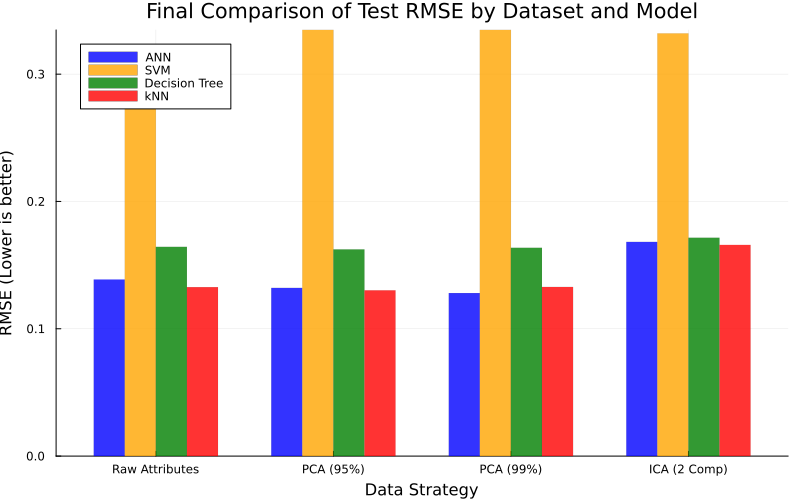

In [55]:
using StatsPlots
using Printf

raw_scores    = [rmse_ann, rmse_svm, rmse_dt, rmse_knn]
pca95_scores  = [rmse_ann_pca95, rmse_svm_pca95, rmse_dt_pca95, rmse_knn_pca95]
pca99_scores  = [rmse_ann_pca99, rmse_svm_pca99, rmse_dt_pca99, rmse_knn_pca99]
ica_scores    = [rmse_ann_ica2, rmse_svm_ica2, rmse_dt_ica2, rmse_knn_ica2]

data_matrix = hcat(raw_scores, pca95_scores, pca99_scores, ica_scores)'

final_data = [
    rmse_ann       rmse_svm       rmse_dt       rmse_knn;
    rmse_ann_pca95 rmse_svm_pca95 rmse_dt_pca95 rmse_knn_pca95;
    rmse_ann_pca99 rmse_svm_pca99 rmse_dt_pca99 rmse_knn_pca99;
    rmse_ann_ica2  rmse_svm_ica2  rmse_dt_ica2  rmse_knn_ica2
]

model_names = ["ANN" "SVM" "Decision Tree" "kNN"]
dataset_names = ["Raw Attributes", "PCA (95%)", "PCA (99%)", "ICA (2 Comp)"]

groupedbar(final_data,
    labels = model_names,
    xticks = (1:4, dataset_names),
    title = "Final Comparison of Test RMSE by Dataset and Model",
    ylabel = "RMSE (Lower is better)",
    xlabel = "Data Strategy",
    bar_position = :dodge,
    bar_width = 0.7,
    alpha = 0.8,
    lw = 0,
    size = (800, 500),
    legend = :topleft,
    color = [:blue :orange :green :red]
)




In [56]:
savefig("final_results_regression.png")
println("Plot saved as 'final_results_regression.png'")

Plot saved as 'final_results_regression.png'


In [68]:
typeof(best_ann_model)

MLJFlux.NeuralNetworkRegressor{MLJFlux.MLP{1}, Adam{Float64, Tuple{Float64, Float64}, Float64}, typeof(Flux.Losses.mse)}

In [85]:
# ==========================================================
# HARD VOTING ENSEMBLES FOR ALL INPUT REPRESENTATIONS
# ==========================================================

# Each entry: dataset name => (X_train, X_test, models::Vector)
ensemble_specs = Dict(
    "Raw Attributes" => (
        X_train = train_input_merge,
        X_test  = test_input,
        models  = [
            best_ann_class_model,
            best_svm_class_model,
            best_dt_class_model,
            best_knn_class_model
        ]
    ),
    "PCA (95% Var)" => (
        X_train = pca_train_merge,
        X_test  = pca_test,
        models  = [
            best_ann_class_model_95,
            best_svm_class_model_95,
            best_dt_class_model_95,
            best_knn_class_model_95
        ]
    ),
    "PCA (99% Var)" => (
        X_train = pca_train_99_merge,
        X_test  = pca_test_99,
        models  = [
            best_ann_class_model_99,
            best_svm_class_model_99,
            best_dt_class_model_99,
            best_knn_class_model_99
        ]
    ),
    "ICA (2 Comp)" => (
        X_train = ica_train_merge,
        X_test  = ica_test,
        models  = [
            best_ann_class_model_ica,
            best_svm_class_model_ica,
            best_dt_class_model_ica,
            best_knn_class_model_ica
        ]
    )
)


println("HARD VOTING ENSEMBLES – CLASSIFICATION")
println("=====================================")

for (name, spec) in ensemble_specs
    Xtr = spec.X_train
    Xte = spec.X_test
    mdl = spec.models

    println("\n>>> Building ensemble for: $name")

    voting_clf = VotingClassifier(
        models = mdl,
        voting = :hard,
        weights = nothing  # uniform weights
    )

    mach = machine(
        voting_clf,
        MLJ.table(Xtr),
        categorical(train_output_binned_merge)
    )

    MLJ.fit!(mach, verbosity=0)

    _ = evaluate_voting_classifier(
        mach,
        Xte,
        test_output_binned;
        title = "Hard Voting Ensemble – $name",
        weighted = false
    )
end


HARD VOTING ENSEMBLES – CLASSIFICATION

>>> Building ensemble for: Raw Attributes

Hard Voting Ensemble – Raw Attributes – Test Results:
Macro Metrics:
Accuracy: 0.592964824120603
Error Rate: 0.40703517587939697
Sensitivity (Recall): 0.5973918947119847
Specificity: 0.8675201124317207
Positive Predictive Value (Precision): 0.6009359201952018
Negative Predictive Value (Precision): 0.8677959274361577
F-score: 0.5837292628345403
Confusion Matrix:
[19 9 9 2; 16 40 1 1; 25 2 18 11; 1 0 4 41]

>>> Building ensemble for: PCA (99% Var)

Hard Voting Ensemble – PCA (99% Var) – Test Results:
Macro Metrics:
Accuracy: 0.5778894472361809
Error Rate: 0.42211055276381915
Sensitivity (Recall): 0.578478961068916
Specificity: 0.8608938833555542
Positive Predictive Value (Precision): 0.5744926893511799
Negative Predictive Value (Precision): 0.8609328772640596
F-score: 0.5699959762459763
Confusion Matrix:
[18 9 3 9; 17 38 2 1; 1 0 37 8; 16 7 11 22]

>>> Building ensemble for: ICA (2 Comp)

Hard Voting Ensem

In [88]:
# ==========================================================
# SOFT VOTING ENSEMBLES (EQUAL WEIGHTS) FOR ALL INPUT REPRESENTATIONS
# ==========================================================

println("\nSOFT VOTING ENSEMBLES – CLASSIFICATION (EQUAL WEIGHTS)")
println("======================================================")

for (name, spec) in ensemble_specs
    Xtr = spec.X_train
    Xte = spec.X_test
    mdl = spec.models

    println("\n>>> Building soft-voting ensemble for: $name")

    soft_voting_clf = VotingClassifier(
        models  = mdl,
        voting  = :soft,
        weights = nothing  # all models equally weighted
    )

    mach = machine(
        soft_voting_clf,
        MLJ.table(Xtr),
        categorical(train_output_binned_merge)
    )

    MLJ.fit!(mach, verbosity=0)

    _ = evaluate_voting_classifier(
        mach,
        Xte,
        test_output_binned;
        title    = "Soft Voting Ensemble (Equal) – $name",
        weighted = false
    )
end



SOFT VOTING ENSEMBLES – CLASSIFICATION (EQUAL WEIGHTS)

>>> Building soft-voting ensemble for: Raw Attributes

Soft Voting Ensemble (Equal) – Raw Attributes – Test Results:
Macro Metrics:
Accuracy: 0.5879396984924623
Error Rate: 0.4120603015075377
Sensitivity (Recall): 0.58566733116958
Specificity: 0.8650327648293855
Positive Predictive Value (Precision): 0.5927352422583531
Negative Predictive Value (Precision): 0.8640269223590892
F-score: 0.5818605368718139
Confusion Matrix:
[18 10 2 9; 13 43 1 1; 1 0 36 9; 26 2 8 20]

>>> Building soft-voting ensemble for: PCA (99% Var)

Soft Voting Ensemble (Equal) – PCA (99% Var) – Test Results:
Macro Metrics:
Accuracy: 0.5678391959798995
Error Rate: 0.4321608040201005
Sensitivity (Recall): 0.5708287683081537
Specificity: 0.8579079460728397
Positive Predictive Value (Precision): 0.5671465789112848
Negative Predictive Value (Precision): 0.8580545523972247
F-score: 0.560556935897948
Confusion Matrix:
[18 9 2 10; 19 36 2 1; 1 0 38 7; 16 6 13 21]

>>>

In [98]:
using Statistics

# data_to_plot already defined above (ANN, SVM, D. Tree, kNN for each preprocessing)
model_names = [m[1] for m in data_to_plot[1][2]]

acc_sums = Dict(name => 0.0 for name in model_names)
counts   = Dict(name => 0   for name in model_names)

for (_ds_name, models) in data_to_plot
    for (m_name, preds, targets) in models
        acc = mean(string.(preds) .== string.(targets))
        acc_sums[m_name] += acc
        counts[m_name]   += 1
    end
end

soft_weights = [acc_sums[name] / counts[name] for name in model_names]
println("Model order: ", model_names)
println("Soft voting weights: ", soft_weights)


Model order: ["ANN", "SVM", "D. Tree", "kNN"]
Soft voting weights: [0.5703517587939698, 0.6105527638190955, 0.5025125628140703, 0.5540201005025125]


In [ ]:
# ==========================================================
# SOFT VOTING ENSEMBLES (WEIGHTED) FOR ALL INPUT REPRESENTATIONS
# ==========================================================

println("\nSOFT VOTING ENSEMBLES – CLASSIFICATION (WEIGHTED)")
println("==================================================")

for (name, spec) in ensemble_specs
    Xtr = spec.X_train
    Xte = spec.X_test
    mdl = spec.models  # [ANN, SVM, DT, kNN] in that fixed order

    println("\n>>> Building soft-voting (weighted) ensemble for: $name")

    soft_voting_clf_weighted = VotingClassifier(
        models  = mdl,
        voting  = :soft,
        weights = soft_weights     # <- NOT nothing now
    )

    mach = machine(
        soft_voting_clf_weighted,
        MLJ.table(Xtr),
        categorical(train_output_binned_merge)
    )

    MLJ.fit!(mach, verbosity = 0)

    _ = evaluate_voting_classifier(
        mach,
        Xte,
        test_output_binned;
        title    = "Soft Voting Ensemble (Weighted) – $name",
        weighted = false
    )
end



SOFT VOTING ENSEMBLES – CLASSIFICATION (WEIGHTED)

>>> Building soft-voting (weighted) ensemble for: Raw Attributes

Soft Voting Ensemble (Weighted) – Raw Attributes – Test Results:
Macro Metrics:
Accuracy: 0.6180904522613065
Error Rate: 0.38190954773869346
Sensitivity (Recall): 0.6071287845088444
Specificity: 0.8727977613576801
Positive Predictive Value (Precision): 0.6034118357487923
Negative Predictive Value (Precision): 0.8736742422675965
F-score: 0.6040654680312125
Confusion Matrix:
[16 11 11 1; 10 46 1 1; 15 6 26 9; 1 0 10 35]

>>> Building soft-voting (weighted) ensemble for: PCA (99% Var)

Soft Voting Ensemble (Weighted) – PCA (99% Var) – Test Results:
Macro Metrics:
Accuracy: 0.6080402010050251
Error Rate: 0.3919597989949749
Sensitivity (Recall): 0.6059272904756414
Specificity: 0.8704405662478253
Positive Predictive Value (Precision): 0.6044944341372913
Negative Predictive Value (Precision): 0.8699632358692762
F-score: 0.6015621919968461
Confusion Matrix:
[18 9 2 10; 15 40 1 

In [104]:
const SVMPlassifier = @load ProbabilisticSVC pkg=LIBSVM

println("\nSTACKING ENSEMBLES – CLASSIFICATION")
println("===================================")

stacking_results = Dict{String, Tuple{Vector{String}, Vector{String}}}()

# Names to assign to the level–0 models
base_model_names = (:ANN, :SVM, :DT, :KNN)

for (name, spec) in ensemble_specs
    Xtr = spec.X_train
    Xte = spec.X_test
    mdl = spec.models   # [best_ann_class_model, best_svm_class_model, best_dt_class_model, best_knn_class_model]

    println("\n>>> Building stacking ensemble for: $name")

    # Build a NamedTuple like (ANN = ann_model, SVM = svm_model, DT = dt_model, KNN = knn_model)
    base_models_nt = (; zip(base_model_names, mdl)...)

    stack_model = Stack(;
        metalearner = SVMPlassifier(),                         # Probabilistic SVC as meta-learner
        resampling  = CV(nfolds = 5, shuffle = true, rng = 123),
        measures    = log_loss,
        base_models_nt...                                      # expand base models as keyword args
    )

    mach = machine(
        stack_model,
        MLJ.table(Xtr),
        categorical(train_output_binned_merge)
    )

    MLJ.fit!(mach, verbosity = 0)

    # Reuse your evaluation helper (works for any classifier, not just VotingClassifier)
    _ = evaluate_voting_classifier(
        mach,
        Xte,
        test_output_binned;
        title    = "Stacking Ensemble – $name",
        weighted = false
    )

    # Store predictions if you later want accuracy plots for stacking
    yhat    = MLJ.predict_mode(mach, MLJ.table(Xte))
    outputs = string.(yhat)
    stacking_results[name] = (outputs, string.(test_output_binned))
end


import MLJLIBSVMInterface ✔

STACKING ENSEMBLES – CLASSIFICATION

>>> Building stacking ensemble for: Raw Attributes

┌ Info: For silent loading, specify `verbosity=0`. 
└ @ Main /Users/albertosc/.julia/packages/MLJModels/ziReN/src/loading.jl:159




Stacking Ensemble – Raw Attributes – Test Results:
Macro Metrics:
Accuracy: 0.6733668341708543
Error Rate: 0.3266331658291457
Sensitivity (Recall): 0.6643177381089675
Specificity: 0.8914134242200575
Positive Predictive Value (Precision): 0.6632324991523368
Negative Predictive Value (Precision): 0.891015902691624
F-score: 0.6634690250810276
Confusion Matrix:
[18 8 1 12; 11 44 1 2; 1 0 39 6; 12 5 6 33]

>>> Building stacking ensemble for: PCA (99% Var)

Stacking Ensemble – PCA (99% Var) – Test Results:
Macro Metrics:
Accuracy: 0.6030150753768844
Error Rate: 0.39698492462311563
Sensitivity (Recall): 0.5990552114052864
Specificity: 0.8685634094993451
Positive Predictive Value (Precision): 0.5859371560642748
Negative Predictive Value (Precision): 0.8702852812636745
F-score: 0.5870281654521555
Confusion Matrix:
[17 11 8 3; 12 43 2 1; 15 5 22 14; 0 0 8 38]

>>> Building stacking ensemble for: ICA (2 Comp)

Stacking Ensemble – ICA (2 Comp) – Test Results:
Macro Metrics:
Accuracy: 0.537688442

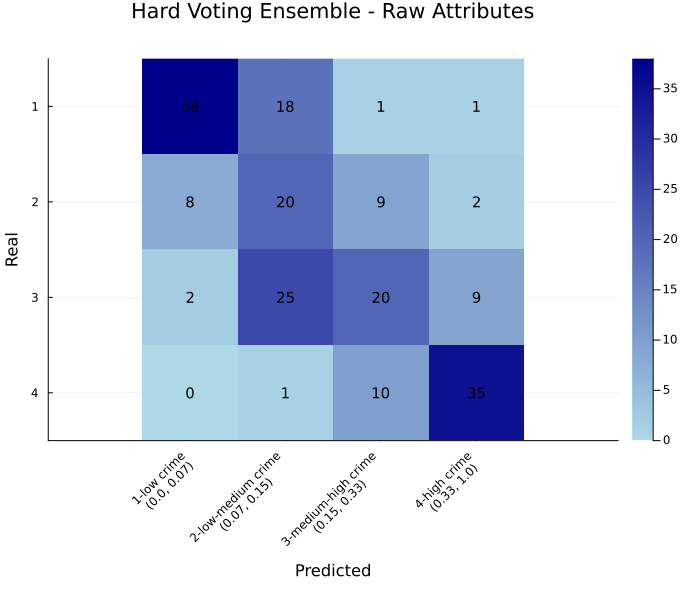

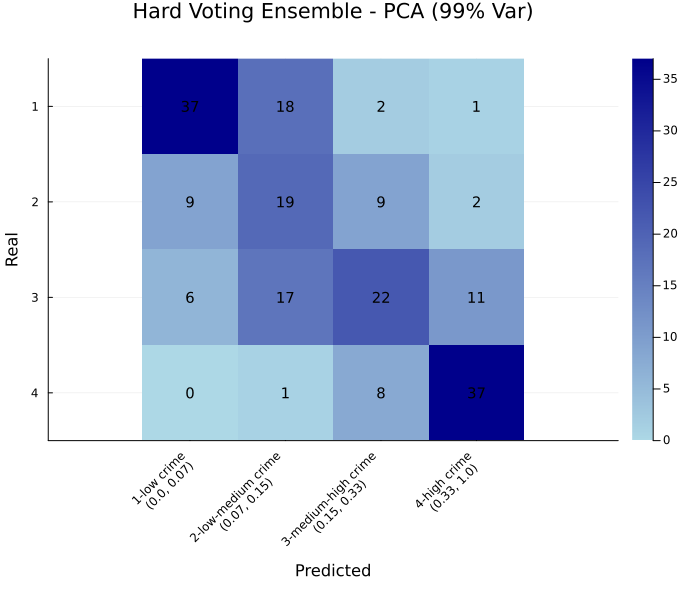

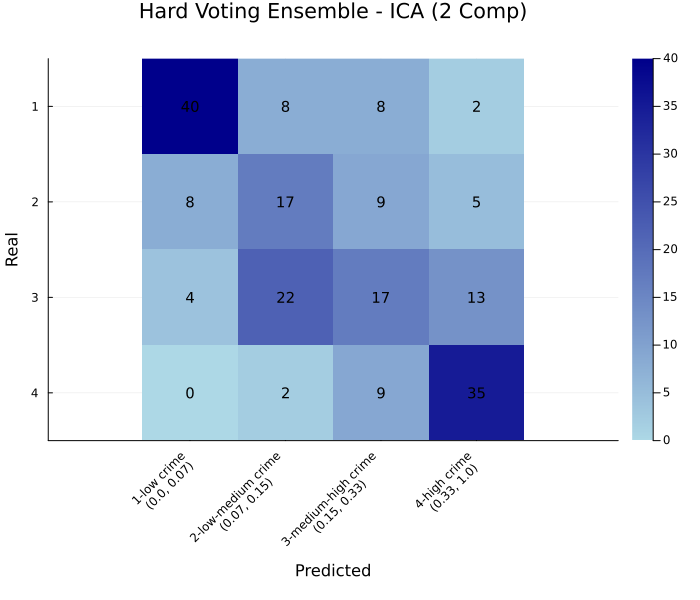

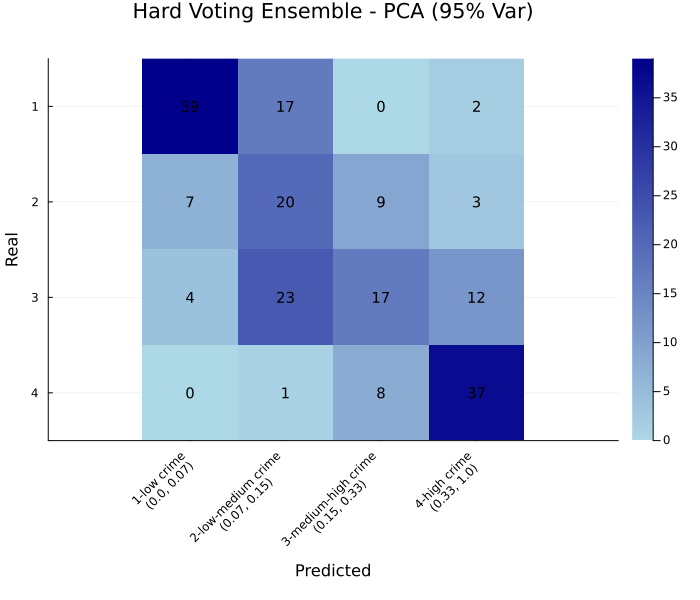

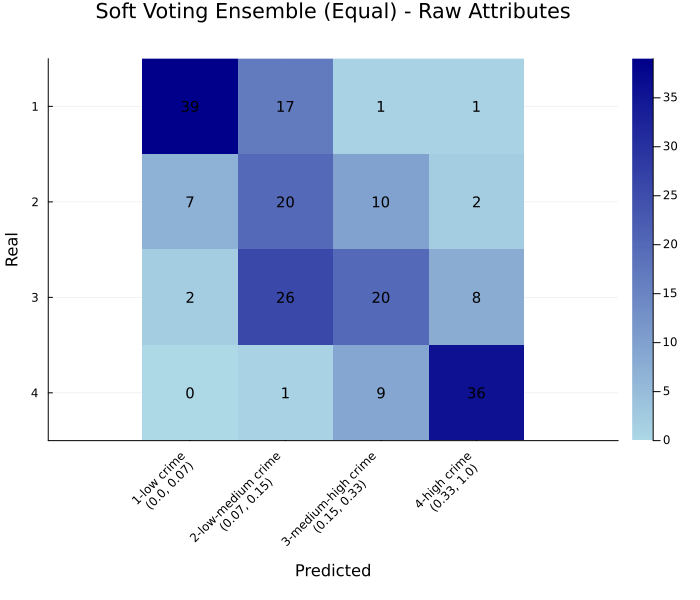

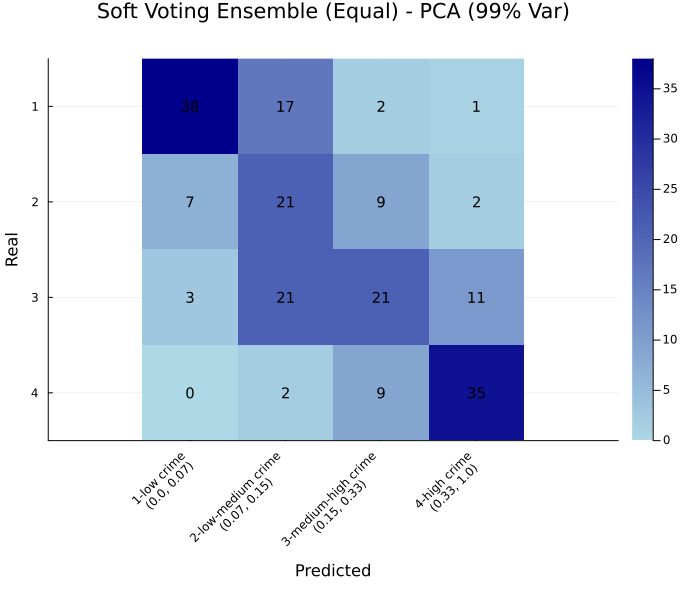

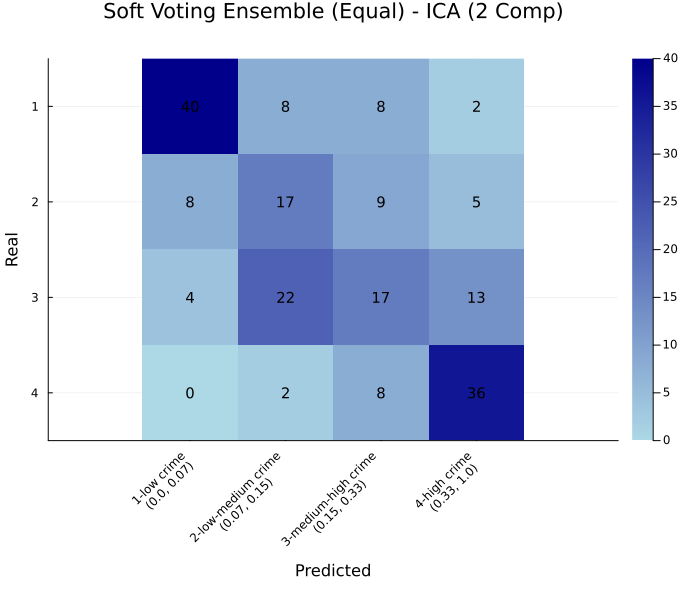

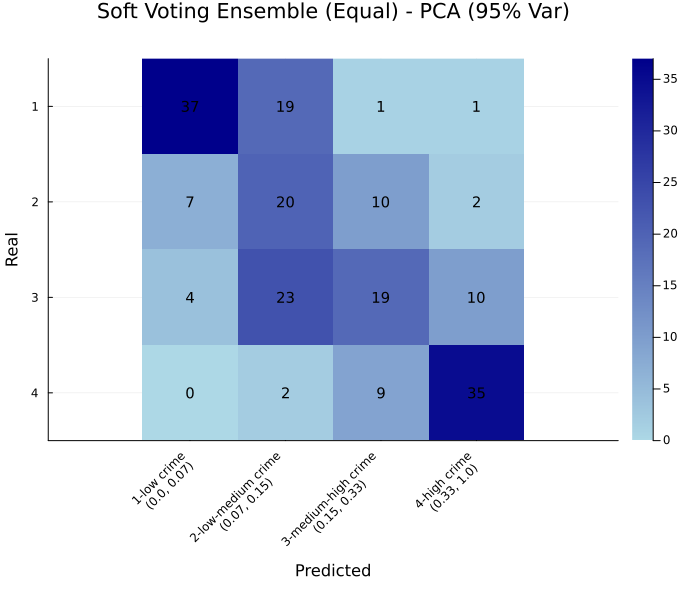

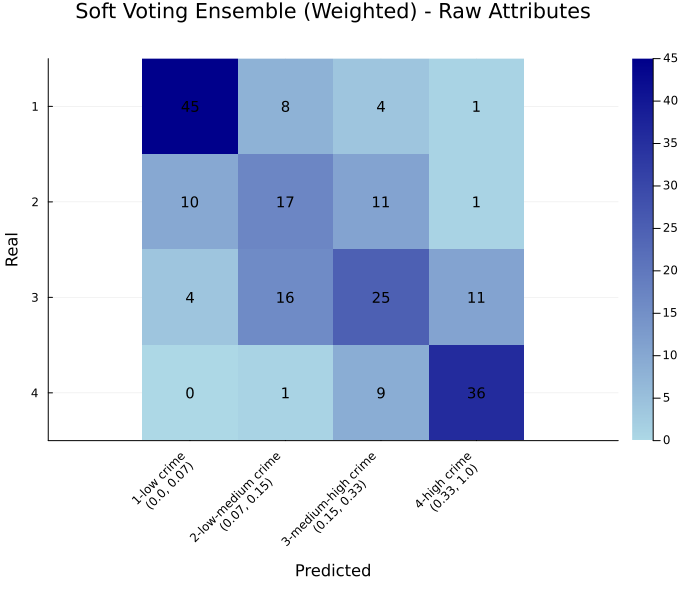

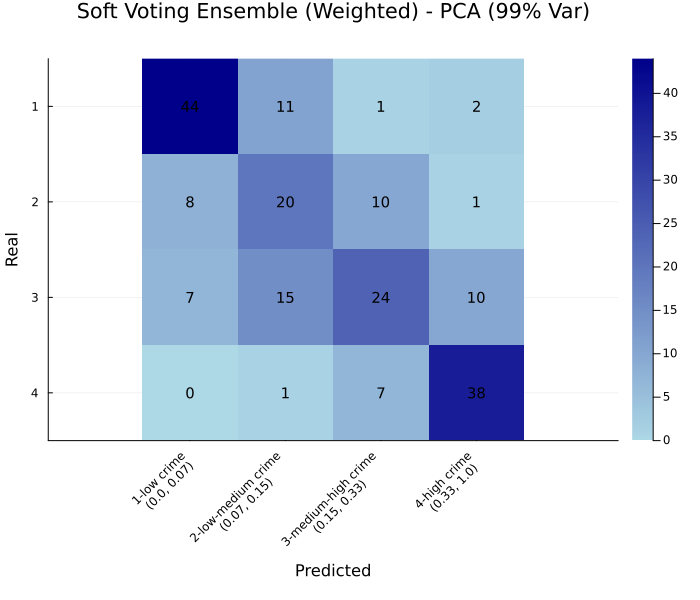

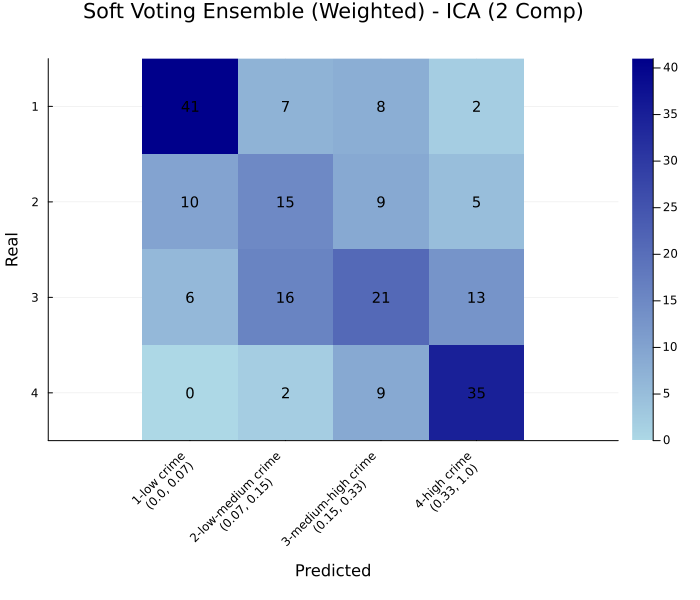

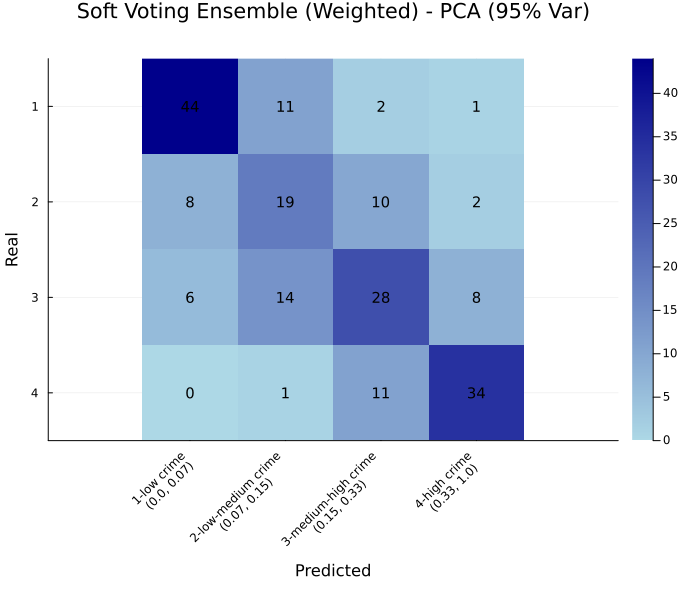

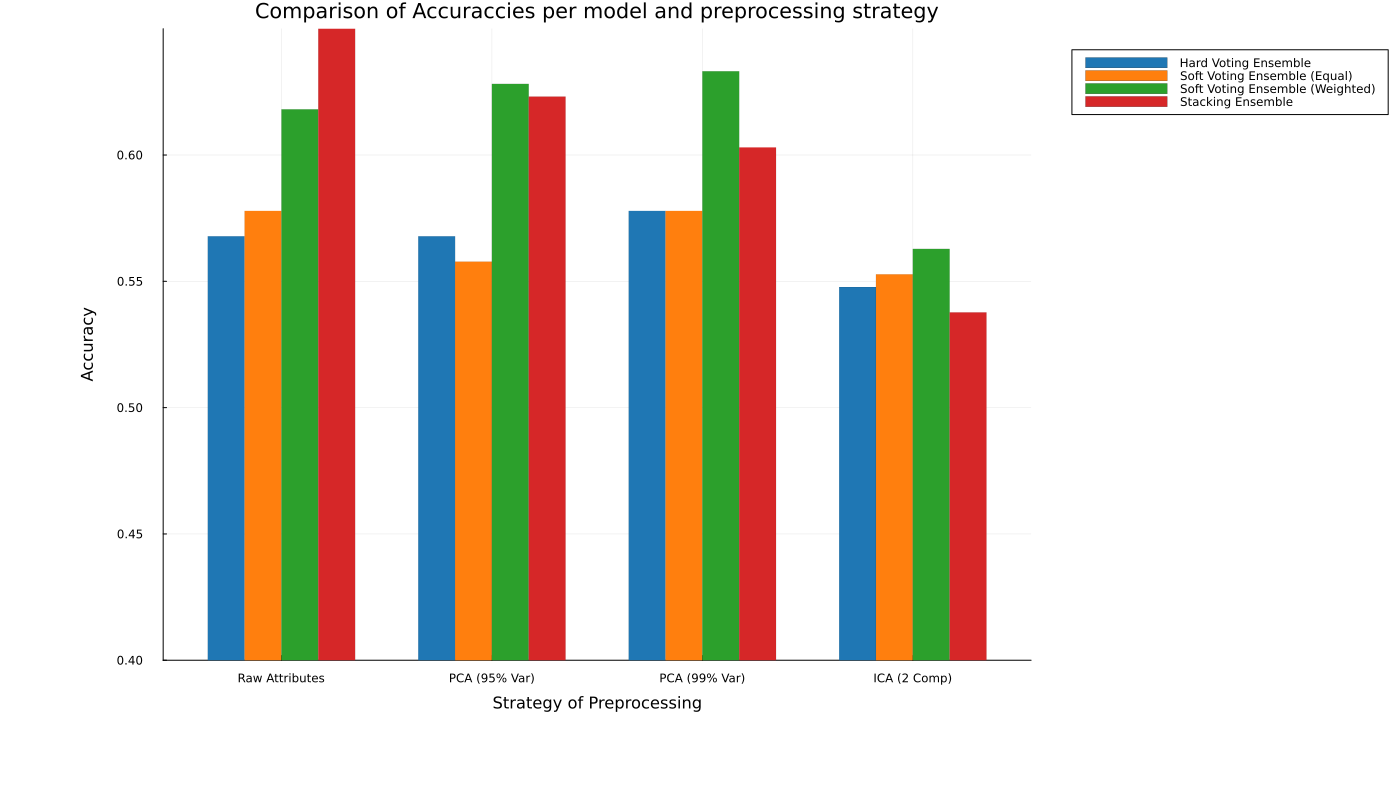

In [105]:
using Statistics

y_train = train_output_binned_merge
y_test  = test_output_binned

ordered_datasets = [
    "Raw Attributes",
    "PCA (95% Var)",
    "PCA (99% Var)",
    "ICA (2 Comp)"
]

# ==========================================================
# 1) HARD VOTING (EQUAL WEIGHTS)
# ==========================================================
ensemble_results_hard = run_voting_ensembles(
    ensemble_specs,
    y_train,
    y_test;
    voting       = :hard,
    weights      = nothing,
    title_prefix = "Hard Voting Ensemble",
    cm_plotter   = plotConfusionMatrix
)

# ==========================================================
# 2) SOFT VOTING (EQUAL WEIGHTS)
# ==========================================================
ensemble_results_soft_equal = run_voting_ensembles(
    ensemble_specs,
    y_train,
    y_test;
    voting       = :soft,
    weights      = nothing,
    title_prefix = "Soft Voting Ensemble (Equal)",
    cm_plotter   = plotConfusionMatrix
)

# ==========================================================
# 3) SOFT VOTING (WEIGHTED)
# ==========================================================
ensemble_results_soft_weighted = run_voting_ensembles(
    ensemble_specs,
    y_train,
    y_test;
    voting       = :soft,
    weights      = soft_weights,
    title_prefix = "Soft Voting Ensemble (Weighted)",
    cm_plotter   = plotConfusionMatrix
)

# ==========================================================
# 4) BUILD DATA FOR ACCURACY COMPARISON (HARD + SOFT + WEIGHTED + STACKING)
# ==========================================================
data_to_plot_ensembles = [
    (
        ds_name,
        [
            ("Hard Voting Ensemble",
                ensemble_results_hard[ds_name][1],
                ensemble_results_hard[ds_name][2]),
            ("Soft Voting Ensemble (Equal)",
                ensemble_results_soft_equal[ds_name][1],
                ensemble_results_soft_equal[ds_name][2]),
            ("Soft Voting Ensemble (Weighted)",
                ensemble_results_soft_weighted[ds_name][1],
                ensemble_results_soft_weighted[ds_name][2]),
            ("Stacking Ensemble",
                stacking_results[ds_name][1],
                stacking_results[ds_name][2])
        ]
    )
    for ds_name in ordered_datasets
]

plotAccuracyComparison(data_to_plot_ensembles)
